## 1. Setup

In [1]:
# !cp /kaggle/input/datasets/rhea568/models-tokenizers/tokenizerv3.pkl .
# !mkdir ./base-models
# !cp /kaggle/input/datasets/rhea568/models-tokenizers/gqa-rope.pt ./base-models/
# !cp /kaggle/input/datasets/rhea568/models-tokenizers/mla-sin.pt ./base-models/
# !cp /kaggle/input/datasets/rhea568/models-tokenizers/gqa-rope-swiglu-moe.pt ./base-models/
# !cp /kaggle/input/datasets/rhea568/models-tokenizers/swiglu-moe-rope-conv.pt ./base-models/

In [2]:
# Imports
import os, gc, copy, time, math, random, re, json, pickle, zipfile, shutil
from dataclasses import dataclass, replace
from collections import defaultdict, Counter

import numpy as np, pandas as pd
from tqdm import tqdm
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score, confusion_matrix
import matplotlib.pyplot as plt

import torch, torch.nn as nn, torch.nn.functional as F
from torch.amp import GradScaler, autocast
from torch.utils.checkpoint import checkpoint

from huggingface_hub import hf_hub_download, login
from kaggle_secrets import UserSecretsClient

# Hugging Face login Secret
login(token=UserSecretsClient().get_secret("HF"))
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Data location
HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
PHASE3_DIR      = "Phase_3_RR"
IGN             = -100        # ignored position in the label tensors (context sentences, padding)
DOMAINS         = ["CL", "IT"]

# "full"     -> complete data and epochs (final runs, submissions)
# "ablation" -> fixed, seeded slice of the data + capped epochs: enough to compare methods quickly
# "smoke"    -> a handful of documents per domain, 1 epoch: verifies the whole pipeline in minutes
RUN_MODE = "full"
RUN_SETTINGS = {"full":     dict(train_frac=1.0, dev_frac=1.0, test_frac=1.0, max_epochs=None, write_test=True),
                "ablation": dict(train_frac=0.3, dev_frac=0.5, test_frac=1.0, max_epochs=3,    write_test=False),
                "smoke":    dict(n_train=8,      n_dev=4,      n_test=4,      max_epochs=1,    write_test=True)}
RS  = RUN_SETTINGS[RUN_MODE]
OUT = {"full": "./cs781_phase3", "ablation": "./cs781_phase3_ablation", "smoke": "./cs781_phase3_smoke"}[RUN_MODE]
os.makedirs(OUT, exist_ok=True)

# Phase 1 model hyper-parameters
VOCAB_SIZE       = 20_000
TRAIN_BLOCK_SIZE = 2048
N_EMBD           = 768
N_LAYER          = 12
N_HEAD           = 12
N_KV_HEAD        = 4
KV_LATENT_DIM    = N_EMBD // 4

PHASE1_CONFIGS = {"gqa-rope":             {"n_layers": 8,  "d_ff": 4 * 768, "attention_type": "gqa", "pos_emb_type": "rope",       "use_moe": False, "use_conv": False},
                  "mla-sin":              {"n_layers": 12, "d_ff": 4 * 768, "attention_type": "mla", "pos_emb_type": "sinusoidal", "use_moe": False, "use_conv": False},
                  "gqa-rope-swiglu-moe":  {"n_layers": 12, "d_ff": 1408,    "attention_type": "gqa", "pos_emb_type": "rope",       "use_moe": True,  "use_conv": False},
                  "swiglu-moe-rope-conv": {"n_layers": 12, "d_ff": 1408,    "attention_type": "gqa", "pos_emb_type": "rope",       "use_moe": True,  "use_conv": True, "local_kernel_size": 25},
                  }
MAIN_MODEL = "gqa-rope-swiglu-moe"   # model used for the technique / ablation experiments

# ── Sentence / context representation ──
MAX_SENT_TOK = 160           # tokens kept per sentence (an </s> is appended)

# ── Training ──
WARMUP_FRAC       = 0.06
MIN_LR_FRAC       = 0.02     # the learning rate never decays below this fraction of its base value
WEIGHT_DECAY      = 0.01
ADAM_BETAS        = (0.9, 0.98)
HEAD_DROPOUT      = 0.1
FOCAL_GAMMA       = 2.0
ADALORA_ORTH_COEF = 0.01
GRAD_CLIP         = 1.0
GRAD_CKPT         = False    # if True, recompute activations in backward -> much lower memory
MOE_AUX           = True     # add the MoE router load-balancing loss to the task loss (MoE Phase 1 models)
MAX_MIN_PER_RUN   = 45       # wall-clock cap per experiment (minutes)

USE_AMP   = DEVICE == "cuda"
AMP_DTYPE = torch.bfloat16 if (USE_AMP and torch.cuda.is_bf16_supported()) else torch.float16
if USE_AMP:
    torch.backends.cuda.matmul.allow_tf32 = True

SEED = 42
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
print(DEVICE, AMP_DTYPE, "| run mode:", RUN_MODE)

cuda torch.bfloat16 | run mode: full


## 2. Tokenizer

In [3]:
class ByteLevelBPE:
    def __init__(self, vocab_size=5000):
        self.vocab_size = vocab_size
        self.reserved = ["<pad>", "<unk>", "<s>", "</s>"]
        self.itos = list(self.reserved); self.stoi = {}; self.merges = []; self.ranks = {}; self.merged_map = {}; self._cache = {}
        # Regex pattern matching words, numbers, individual punctuation, and whitespace sequences
        self.pattern = r"""'s|'t|'re|'ve|'m|'ll|'d| ?[^\s\W\d_]+| ?\d+| ?[^\s\w]+|\s+(?!\S)|\s+"""
        self.pat = re.compile(self.pattern, re.UNICODE)

    def fit(self, texts, max_unique_words=200000):
        """Train a byte-level BPE tokenizer using inverted indexing for fast merging."""
        raw_counts = Counter()
        iterator = [texts] if isinstance(texts, str) else texts

        # Preserve whitespace tokens when populating initial raw_counts
        for text in tqdm(iterator, desc="Building word vocabulary"):
            for chunk in re.findall(self.pattern, str(text), flags=re.UNICODE):
                raw_counts[chunk] += 1

        if max_unique_words and len(raw_counts) > max_unique_words:
            most_common = raw_counts.most_common(max_unique_words)
            raw_counts = dict(most_common)

        word_freqs = {}; pair_counts = defaultdict(int); pair_to_words = defaultdict(set)
        for word, count in raw_counts.items():
            encoded = word.encode("utf-8")
            byte_word = tuple(encoded[i:i+1] for i in range(len(encoded)))
            word_freqs[byte_word] = count

            for i in range(len(byte_word) - 1):
                pair = (byte_word[i], byte_word[i + 1])
                pair_counts[pair] += count
                pair_to_words[pair].add(byte_word)

        base_bytes = sorted({token for word in word_freqs for token in word})
        self.itos = list(self.reserved) + base_bytes; self.merges = []
        target_merges = self.vocab_size - len(self.itos)

        with tqdm(total=target_merges, desc="Training BPE Merges") as pbar:
            while len(self.itos) < self.vocab_size:
                if not pair_counts:
                    break
                best_pair = max(pair_counts, key=lambda p: (pair_counts[p], p[0], p[1]))
                if pair_counts[best_pair] <= 0:
                    break
                merged_token = best_pair[0] + best_pair[1]
                self.merges.append((best_pair, merged_token))
                self.itos.append(merged_token)
                
                words_to_update = list(pair_to_words[best_pair])
                del pair_counts[best_pair]
                del pair_to_words[best_pair]

                p0, p1 = best_pair
                for word in words_to_update:
                    count = word_freqs.get(word, 0)
                    if count == 0:
                        continue

                    new_word = []; i = 0; n = len(word)
                    while i < n:
                        if i + 1 < n and word[i] == p0 and word[i + 1] == p1:
                            new_word.append(merged_token)
                            i += 2
                        else:
                            new_word.append(word[i])
                            i += 1
                    new_word = tuple(new_word)
                    
                    for j in range(len(word) - 1):
                        old_p = (word[j], word[j + 1])
                        if old_p in pair_counts:
                            pair_counts[old_p] -= count
                            if pair_counts[old_p] <= 0:
                                del pair_counts[old_p]

                    for j in range(len(new_word) - 1):
                        new_p = (new_word[j], new_word[j + 1])
                        pair_counts[new_p] += count
                        pair_to_words[new_p].add(new_word)

                    del word_freqs[word]
                    word_freqs[new_word] = count

                pbar.update(1)

        self.vocab_size = len(self.itos)
        self.stoi = {token: idx for idx, token in enumerate(self.itos)}
        self.ranks = {pair: rank for rank, (pair, _) in enumerate(self.merges)}
        self.merged_map = {pair: merged for pair, merged in self.merges}
        self._cache = {}
        return self

    def encode_word(self, word):
        """Encode single word using memoization and local pair updates."""
        if word in self._cache:
            return self._cache[word]

        encoded = word.encode("utf-8")
        tokens = [encoded[i:i+1] for i in range(len(encoded))]

        if len(tokens) <= 1:
            res = [self.stoi.get(token, self.stoi["<unk>"]) for token in tokens]
            self._cache[word] = res
            return res

        while len(tokens) > 1:
            min_rank = float("inf")
            min_pair = None

            for i in range(len(tokens) - 1):
                pair = (tokens[i], tokens[i + 1])
                rank = self.ranks.get(pair, float("inf"))
                if rank < min_rank:
                    min_rank = rank
                    min_pair = pair

            if min_pair is None or min_rank == float("inf"):
                break

            merged = self.merged_map[min_pair]
            new_tokens = []
            i = 0
            n = len(tokens)
            p0, p1 = min_pair

            while i < n:
                if i + 1 < n and tokens[i] == p0 and tokens[i + 1] == p1:
                    new_tokens.append(merged)
                    i += 2
                else:
                    new_tokens.append(tokens[i])
                    i += 1
            tokens = new_tokens

        res = [self.stoi.get(token, self.stoi["<unk>"]) for token in tokens]
        self._cache[word] = res
        return res

    def encode(self, text):
        """Encode a sentence while preserving original spaces and newlines."""
        ids = [self.stoi["<s>"]]
        pattern = r"""'s|'t|'re|'ve|'m|'ll|'d| ?[^\s\W\d_]+| ?\d+| ?[^\s\w]+|\s+(?!\S)|\s+"""
        for chunk in re.findall(pattern, str(text), flags=re.UNICODE):
            ids.extend(self.encode_word(chunk))
        ids.append(self.stoi["</s>"])
        return ids
    
    def decode(self, ids):
        """Decode BPE token IDs back into text seamlessly."""
        byte_list = []
        for idx in ids:
            tok = self.itos[idx] if 0 <= idx < len(self.itos) else "<unk>"
            if tok not in self.reserved and isinstance(tok, bytes):
                byte_list.append(tok)
        try:
            return b"".join(byte_list).decode("utf-8", errors="ignore")
        except Exception:
            return ""

    def get_vocab_size(self):
        return self.vocab_size

def train_tokenizer(train_text: str, vocab_size: int):
    """Train A-1 BPE tokenizer on `train_text` and return the trained tokenizer."""
    tokenizer = ByteLevelBPE(vocab_size)
    tokenizer.fit(train_text)
    return tokenizer
    
# Load Pretrained Tokenizer
with open("tokenizerv3.pkl", "rb") as f:
    tokenizer = pickle.load(f)
BOS, PAD, UNK, EOS = (tokenizer.stoi[t] for t in ("<s>", "<pad>", "<unk>", "</s>"))
assert len(tokenizer.itos) == VOCAB_SIZE
print("tokenizer vocab:", len(tokenizer.itos))

tokenizer vocab: 20000


## 3. Model Class Definitions

In [4]:
@dataclass
class LMConfig:
    vocab_size: int = VOCAB_SIZE
    d_model: int = N_EMBD
    n_layers: int = N_LAYER
    n_heads: int = N_HEAD
    n_kv_heads: int = N_KV_HEAD
    kv_latent_dim: int = KV_LATENT_DIM
    d_ff: int = 1408          # For SwiGLU (2/3) * 4 * d_model => 2/3 * 2048 = 1365 --> round to nearest upper multiple of 64 (1408)
    max_seq_len: int  = TRAIN_BLOCK_SIZE
    dropout: float = 0.0            # ~1 pass over the data -> no need for dropout
    pos_emb_type: str = "rope"      # "rope" or "sinusoidal"
    attention_scale: float = None
    norm_first: bool = True         # FIX: pre-LN (post-LN + lr 1e-3 + no warm-up is unstable)
    n_experts:  int   = 4
    top_k:      int   = 2
    aux_loss_coef: float = 0.01
    attention_type: str = "gqa"
    use_moe: bool = False, 
    use_conv: bool = False
    local_kernel_size: int = 25
    
# Rotary Positional Embeddings
def build_rope_cache(max_seq_len: int, d_head: int, base: float = 10000.0):
    """ Returns (cos, sin) : the split-half rotate_half convention: channel i is paired with channel i+d_head/2. """
    inv = 1.0 / (base ** (torch.arange(0, d_head, 2).float() / d_head))
    ang = torch.cat([torch.outer(torch.arange(max_seq_len).float(), inv)] * 2, -1)
    return ang.cos(), ang.sin()
def rotate_half(x: torch.Tensor) -> torch.Tensor:
    """Split the last dim in half and return (-x2, x1) concatenated -- the 90-degree rotation step used by the "rotate_half" formulation of RoPE."""
    x1, x2 = x[ ..., : x.shape[-1] // 2], x[..., x.shape[-1] // 2 : ]
    return torch.cat((-x2, x1), dim = -1)
def apply_rope(x: torch.Tensor, cos: torch.Tensor, sin: torch.Tensor) -> torch.Tensor:
    """ x: (B, n_heads, T, d_head) -- a query or key tensor. cos, sin: (T, d_head), sliced from build_rope_cache's output for the current T. Returns the rotated tensor, same shape as x. Formula: x_rotated = x * cos + rotate_half(x) * sin """
    cos, sin = (cos[None, None], sin[None, None]) if cos.dim() == 2 else (cos[:, None], sin[:, None])
    return x.float() * cos + rotate_half(x.float()) * sin

def sinusoidal_positional_encoding(max_len: int, d_model: int) -> torch.Tensor:
    pos = torch.arange(max_len, dtype=torch.float32).unsqueeze(1)
    i = torch.arange(0, d_model, 2, dtype=torch.float32)
    angle = pos / (10000 ** (i / d_model))
    return torch.stack([torch.sin(angle), torch.cos(angle)], dim=-1).reshape(max_len, d_model)

class CausalSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads, n_kv_heads, max_seq_len, dropout=0.0, use_rope=True, attention_scale=None):
        super().__init__()
        assert d_model % n_heads == 0 and n_heads % n_kv_heads == 0
        self.n_heads, self.n_kv_heads = n_heads, n_kv_heads
        self.n_rep, self.d_head = n_heads // n_kv_heads, d_model // n_heads
        self.use_rope = use_rope
        self.attention_scale = (1.0 / math.sqrt(self.d_head)) if attention_scale is None else float(attention_scale)

        self.q_proj = nn.Linear(d_model, n_heads * self.d_head, bias=False)
        self.k_proj = nn.Linear(d_model, n_kv_heads * self.d_head, bias=False)
        self.v_proj = nn.Linear(d_model, n_kv_heads * self.d_head, bias=False)
        self.out_proj = nn.Linear(n_heads * self.d_head, d_model, bias=False)
        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)

        if use_rope:
            cos, sin = build_rope_cache(max_seq_len, self.d_head)
            self.register_buffer("rope_cos", cos, persistent=False)
            self.register_buffer("rope_sin", sin, persistent=False)

    def forward(self, x, position_ids=None, attn_mask=None, kv_cache=None, use_cache=False):
        B, T, C = x.shape
        q = self.q_proj(x).view(B, T, self.n_heads, self.d_head).transpose(1, 2)
        k = self.k_proj(x).view(B, T, self.n_kv_heads, self.d_head).transpose(1, 2)
        v = self.v_proj(x).view(B, T, self.n_kv_heads, self.d_head).transpose(1, 2)

        if self.use_rope:
            q = apply_rope(q, self.rope_cos[position_ids], self.rope_sin[position_ids])
            k = apply_rope(k, self.rope_cos[position_ids], self.rope_sin[position_ids])
             
        # Append to KV cache if provided
        if kv_cache is not None:
            past_k, past_v = kv_cache
            k = torch.cat([past_k, k], dim=-2)
            v = torch.cat([past_v, v], dim=-2)
        new_kv_cache = (k, v) if use_cache else None

        if self.n_rep > 1:
            k = k.repeat_interleave(self.n_rep, dim=1)
            v = v.repeat_interleave(self.n_rep, dim=1)

        # Only set is_causal=True if processing multiple prompt tokens at once (T > 1)
        is_causal = (attn_mask is None) and (kv_cache is None) and (T > 1)
        context = F.scaled_dot_product_attention(q, k, v, attn_mask=attn_mask, dropout_p=self.attn_dropout.p if self.training else 0.0,  is_causal=is_causal, scale=self.attention_scale)
        out = self.resid_dropout(self.out_proj(context.transpose(1, 2).reshape(B, T, C)))
        
        return (out, new_kv_cache) if use_cache else out

class MultiHeadLatentAttention(nn.Module):
    """Joint KV Compression Multi-Head Latent Attention module drop-in replacement for CausalSelfAttention."""

    def __init__(self, d_model, n_heads, kv_latent_dim, max_seq_len, dropout=0.0, attention_scale=None):
        super().__init__()
        assert (d_model % n_heads == 0 and 0 < kv_latent_dim < d_model), "d_model must be divisible by n_heads, and 0 < kv_latent_dim < d_model"

        self.n_heads, self.kv_latent_dim, self.d_head = n_heads, kv_latent_dim, d_model // n_heads
        self.attention_scale = ((1.0 / math.sqrt(self.d_head)) if attention_scale is None else float(attention_scale))

        # Projections
        self.q_proj = nn.Linear(d_model, d_model, bias=False)
        self.kv_down_proj = nn.Linear(d_model, kv_latent_dim, bias=False)
        self.k_up_proj = nn.Linear(kv_latent_dim, d_model, bias=False)
        self.v_up_proj = nn.Linear(kv_latent_dim, d_model, bias=False)
        self.out_proj = nn.Linear(d_model, d_model, bias=False)
        # Dropouts
        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)

    def forward(self, x, position_ids=None, attn_mask=None, kv_cache=None, use_cache=False):
        """Forward pass supporting sequence generation with KV cache and FlashAttention/SDPA."""
        B, T, C = x.shape
        q = (self.q_proj(x).reshape(B, T, self.n_heads, self.d_head).transpose(1, 2))  # (B, n_heads, T, d_head)
        c_kv = self.kv_down_proj(x)  # (B, T, kv_latent_dim)

        if kv_cache is not None:
            past_c_kv = (kv_cache[0] if isinstance(kv_cache, (tuple, list)) else kv_cache)
            c_kv = torch.cat([past_c_kv, c_kv], dim=1)  # Append along sequence dim T
        new_kv_cache = (c_kv,) if use_cache else None

        k = (self.k_up_proj(c_kv).view(B, -1, self.n_heads, self.d_head).transpose(1, 2))  # (B, n_heads, T_total, d_head)
        v = (self.v_up_proj(c_kv).view(B, -1, self.n_heads, self.d_head).transpose(1, 2))  # (B, n_heads, T_total, d_head)
        is_causal = (attn_mask is None) and (kv_cache is None) and (T > 1)
        
        context = F.scaled_dot_product_attention(q, k, v, attn_mask=attn_mask, dropout_p=self.attn_dropout.p if self.training else 0.0, is_causal=is_causal, scale=self.attention_scale)
        out = context.transpose(1, 2).contiguous().view(B, T, C)
        out = self.resid_dropout(self.out_proj(out))

        return (out, new_kv_cache) if use_cache else out

### Model Definitions
class FeedForward(nn.Module):
    def __init__(self, d_model: int, d_ff: int, dropout: float):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_model, d_ff), nn.GELU(), nn.Linear(d_ff, d_model), nn.Dropout(dropout))
    def forward(self, x):
        return self.net(x)
        
class SwiGLUFeedForward(nn.Module):
    def __init__(self, d_model: int, d_ff: int, dropout: float):
        super().__init__()
        self.gate = nn.Linear(d_model, d_ff, bias=False); self.up   = nn.Linear(d_model, d_ff, bias=False); self.down = nn.Linear(d_ff, d_model, bias=False); self.drop = nn.Dropout(dropout)
    def forward(self, x):
        return self.drop(self.down(F.silu(self.gate(x)) * self.up(x)))

class TopKRouter(nn.Module):
    def __init__(self, d_model: int, n_experts: int, top_k: int):
        super().__init__()
        self.top_k  = top_k; self.linear = nn.Linear(d_model, n_experts, bias=False)
    def forward(self, x_flat):                           
        logits = self.linear(x_flat); topk_vals, topk_idx = torch.topk(logits, self.top_k, dim=-1)
        weights = F.softmax(topk_vals, dim=-1)            # (B*T, top_k)
        dispatch = torch.zeros_like(logits, dtype=weights.dtype)
        dispatch.scatter_(-1, topk_idx, weights)          # (B*T, n_experts)
        return dispatch, logits                           # logits kept for aux loss

class MoEFeedForward(nn.Module):
    def __init__(self, d_model, d_ff, n_experts, top_k, dropout, aux_coef=0.01):
        super().__init__()
        self.router   = TopKRouter(d_model, n_experts, top_k)
        self.experts  = nn.ModuleList([SwiGLUFeedForward(d_model, d_ff, dropout) for _ in range(n_experts)])
        self.aux_coef = aux_coef; self.aux_loss = torch.tensor(0.0)

    def forward(self, x):
        B, T, D = x.shape
        x_flat = x.reshape(B * T, D)
        dispatch, router_logits = self.router(x_flat)

        z = torch.logsumexp(router_logits, dim=-1)
        self.aux_loss = self.aux_coef * (z ** 2).mean()
        out = torch.zeros_like(x_flat)
        for e_idx, expert in enumerate(self.experts):
            w  = dispatch[:, e_idx];  mask = w > 0
            if not mask.any():
                continue
            out[mask] += w[mask].unsqueeze(-1) * expert(x_flat[mask])

        return out.reshape(B, T, D)

class Block(nn.Module):
    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.norm_first = cfg.norm_first; self.ln1 = nn.LayerNorm(cfg.d_model); self.ln2 = nn.LayerNorm(cfg.d_model)
        if(cfg.attention_type == "mla"):
            self.attn = MultiHeadLatentAttention(cfg.d_model, cfg.n_heads, cfg.kv_latent_dim, cfg.max_seq_len, cfg.dropout, attention_scale=cfg.attention_scale)
        else:
            self.attn = CausalSelfAttention(cfg.d_model, cfg.n_heads, cfg.n_kv_heads, cfg.max_seq_len, cfg.dropout, use_rope=(cfg.pos_emb_type == "rope"), attention_scale=cfg.attention_scale)
        if(cfg.use_moe):
            self.ffn  = MoEFeedForward(cfg.d_model, cfg.d_ff, cfg.n_experts, cfg.top_k, cfg.dropout, cfg.aux_loss_coef)
        else:
            self.ffn = FeedForward(cfg.d_model, cfg.d_ff, cfg.dropout)
        
    def _attn(self, h, position_ids, attn_mask, kv_cache, use_cache):
        r = self.attn(h, position_ids=position_ids, attn_mask=attn_mask, kv_cache=kv_cache, use_cache=use_cache)
        return r if use_cache else (r, None)
        
    def forward(self, x, position_ids, attn_mask=None, kv_cache=None, use_cache=False):
        if self.norm_first:
            a, new_cache = self._attn(self.ln1(x), position_ids, attn_mask, kv_cache, use_cache)
            x = x + a
            x = x + self.ffn(self.ln2(x))
        else:
            a, new_cache = self._attn(x, position_ids, attn_mask, kv_cache, use_cache)
            x = self.ln1(x + a)
            x = self.ln2(x + self.ffn(x))
        return x, new_cache
        
class LocalDepthwiseConv(nn.Module):
    """ Depthwise causal convolution over the sequence dimension. Acts on each channel independently — O(T * C * kernel) cost. kernel_size = 25 covers ~25 tokens of local context. """
    def __init__(self, d_model: int, kernel_size: int = 25, dropout: float = 0.0):
        super().__init__()
        self.kernel_size = kernel_size
        self.conv = nn.Conv1d(in_channels=d_model, out_channels=d_model, kernel_size=kernel_size, padding=0, groups=d_model, bias=False)
        self.proj = nn.Linear(d_model, d_model, bias=False)
        self.drop = nn.Dropout(dropout)
        nn.init.normal_(self.conv.weight, 0.0, 0.02)
        nn.init.normal_(self.proj.weight, 0.0, 0.02)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """x: (B, T, C) → (B, T, C)"""
        B, T, C = x.shape
        xc = x.transpose(1, 2)
        xc = F.pad(xc, (self.kernel_size - 1, 0))
        xc = self.conv(xc)          # (B, C, T)  — output length = T (causal)
        xc = xc.transpose(1, 2)    # (B, T, C)
        return self.drop(self.proj(F.gelu(xc)))

class ParallelLocalGlobalBlock(nn.Module):
    """Pre-LN block with global attention and local conv running IN PARALLEL."""
    def __init__(self, cfg):
        super().__init__()
        self.ln1  = nn.RMSNorm(cfg.d_model); self.ln2  = nn.RMSNorm(cfg.d_model)
        self.attn = CausalSelfAttention(cfg.d_model, cfg.n_heads, cfg.n_kv_heads, cfg.max_seq_len, cfg.dropout, use_rope=cfg.pos_emb_type == "rope", attention_scale=cfg.attention_scale)
        self.conv = LocalDepthwiseConv(cfg.d_model, kernel_size=cfg.local_kernel_size, dropout=cfg.dropout)
        self.ffn  = MoEFeedForward(cfg.d_model, cfg.d_ff, cfg.n_experts, cfg.top_k, cfg.dropout, cfg.aux_loss_coef)
        self.alpha = nn.Parameter(torch.ones(1))    # global attention scale
        self.beta  = nn.Parameter(torch.full((1,), 0.1))  # local conv scale

    def forward(self, x, position_ids, attn_mask=None, kv_cache=None, use_cache=False):
        normed = self.ln1(x)
        attn_out = self.attn(normed, position_ids=position_ids, attn_mask=attn_mask, kv_cache=kv_cache, use_cache=use_cache)
        attn_out, new_cache = attn_out if use_cache else attn_out, None
        conv_out = self.conv(normed)
        
        x = x + self.alpha * attn_out + self.beta * conv_out
        x = x + self.ffn(self.ln2(x))
        return x, new_cache

    @property
    def aux_loss(self):
        return self.ffn.aux_loss


class DecoderLM(nn.Module):
    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.cfg = cfg
        self.use_sin = cfg.pos_emb_type == "sinusoidal"
        self.emb_scale = math.sqrt(cfg.d_model) if self.use_sin else 1.0
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        if self.use_sin:
            self.register_buffer("pos_emb", sinusoidal_positional_encoding(cfg.max_seq_len, cfg.d_model), persistent=False)
        if cfg.use_conv:
            self.blocks = nn.ModuleList([ParallelLocalGlobalBlock(cfg) for _ in range(cfg.n_layers)])
        else:
            self.blocks = nn.ModuleList([Block(cfg) for _ in range(cfg.n_layers)])
        
        self.ln_f = nn.LayerNorm(cfg.d_model)
        self.head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        self._init_weights()
        self.head.weight = self.tok_emb.weight # tie AFTER init so the embedding init survives

    def aux_loss(self):
        return sum(blk.ffn.aux_loss for blk in self.blocks)
        
    def _init_weights(self):
        emb_std = self.cfg.d_model ** -0.5 if self.use_sin else 0.02
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.normal_(m.weight, mean=0.0, std=0.02)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Embedding):
                nn.init.normal_(m.weight, mean=0.0, std=emb_std)
        for n, p in self.named_parameters():
            if n.endswith("attn.out_proj.weight") or n.endswith("ffn.net.2.weight"):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * self.cfg.n_layers))
    
    def forward(self, idx: torch.Tensor, kv_cache_list=None, use_cache=False, attention_mask=None) -> torch.Tensor:
        """attention_mask: optional (B, past+T) tensor, 1 = real token, 0 = left padding."""
        B, T = idx.shape
        past = kv_cache_list[0][0].shape[-2] if kv_cache_list is not None else 0
        S = past + T

        if attention_mask is None:
            position_ids = torch.arange(past, S, device=idx.device).unsqueeze(0).expand(B, T)
            attn_mask = None                                   # fast path: is_causal=True inside SDPA
        else:
            position_ids = (attention_mask.long().cumsum(-1) - 1).clamp(min=0)[:, past:S]
            q_idx = torch.arange(past, S, device=idx.device)[:, None]
            k_idx = torch.arange(S, device=idx.device)[None, :]
            allowed = (k_idx <= q_idx)[None] & attention_mask[:, None, :S].bool()   # causal & not-padding
            allowed = allowed | (k_idx == q_idx)[None]         # pad rows attend to themselves (no NaNs)
            attn_mask = allowed.unsqueeze(1)                   # (B, 1, T, S)

        x = self.tok_emb(idx) * self.emb_scale
        if self.use_sin:
            x = x + self.pos_emb[position_ids]

        new_caches = []
        for i, block in enumerate(self.blocks):
            layer_cache = kv_cache_list[i] if kv_cache_list is not None else None
            x, c = block(x, position_ids, attn_mask, layer_cache, use_cache)
            new_caches.append(c)

        logits = self.head(self.ln_f(x))
        return (logits, new_caches) if use_cache else logits
        
    @torch.no_grad()
    def generate(self, input_ids, attention_mask=None, max_new_tokens=384, temperature=0.7, top_p=0.9,
                 repetition_penalty=1.0, banned_token_ids=(0, 1, 2, 3), do_sample=True):
        self.eval()
        out = input_ids
        if attention_mask is None:
            attention_mask = torch.ones_like(out)
    
        logits, kv = self(out, use_cache=True, attention_mask=attention_mask)      # prefill
        next_logits = logits[:, -1, :].float()
    
        for step in range(max_new_tokens):
            l = next_logits.clone()
            if repetition_penalty != 1.0:
                sc = l.gather(1, out); sc = torch.where(sc < 0, sc * repetition_penalty, sc / repetition_penalty)
                l = l.scatter(1, out, sc)
            if banned_token_ids:                       # never emit <pad>/<unk>/<s>/</s>: we need 128 words
                l[:, list(banned_token_ids)] = float("-inf")

            if do_sample and temperature > 0.0:
                l = l / temperature
                if top_p < 1.0:
                    sorted_logits, sorted_idx = torch.sort(l, descending=True)
                    cum = torch.cumsum(F.softmax(sorted_logits, dim=-1), dim=-1)
                    remove = cum > top_p
                    remove[..., 1:] = remove[..., :-1].clone()
                    remove[..., 0] = False
                    l = l.masked_fill(remove.scatter(1, sorted_idx, remove), float("-inf"))
                next_token = torch.multinomial(F.softmax(l, dim=-1), num_samples=1)
            else:
                next_token = l.argmax(dim=-1, keepdim=True)

            out = torch.cat([out, next_token], dim=1)
            attention_mask = torch.cat([attention_mask, torch.ones_like(next_token)], dim=1)
            if step == max_new_tokens - 1:
                break
            logits, kv = self(next_token, kv_cache_list=kv, use_cache=True, attention_mask=attention_mask)
            next_logits = logits[:, -1, :].float()
        return out

## 4. Data Loading

In [5]:
def load_phase1_model(model_name):
    cfg = LMConfig()
    for attr, val in PHASE1_CONFIGS[model_name].items():
        setattr(cfg, attr, val)

    checkpoint_data = torch.load(f"./base-models/{model_name}.pt", map_location="cpu", weights_only=False)
    base_lm = DecoderLM(cfg)
    base_lm.load_state_dict(checkpoint_data["model"], strict=True)
    del checkpoint_data; gc.collect()
    return base_lm

def subset_docs(docs, frac=None, n=None, seed=SEED):
    """Fixed, seeded subset of a {doc_id: ...} dict (used by the ablation / smoke modes). Full mode returns it unchanged."""
    keys = list(docs)
    k = n if n is not None else (len(keys) if frac is None else max(1, round(len(keys) * frac)))
    if k >= len(keys):
        return docs
    pick = sorted(np.random.RandomState(seed).choice(len(keys), k, replace=False))
    return {keys[i]: docs[keys[i]] for i in pick}

def read_json(relative_path):
    path = hf_hub_download(repo_id=HF_DATASET_REPO, repo_type="dataset", filename=f"{PHASE3_DIR}/{relative_path}")
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)

lv = read_json("Train/label_vocab.json")
if isinstance(lv, dict):
    if "labels" in lv and isinstance(lv["labels"], list):
        LABELS = lv["labels"]
    elif all(isinstance(v, int) for v in lv.values()):
        LABELS = [k for k, _ in sorted(lv.items(), key=lambda kv: kv[1])]
    else:
        LABELS = list(lv.keys())
else:
    LABELS = list(lv)
LABELS = [str(x) for x in LABELS]
L2I = {l: i for i, l in enumerate(LABELS)}
NUM_LABELS = len(LABELS)
print(NUM_LABELS, "labels:", LABELS)

def encode_sentence(text, max_len=MAX_SENT_TOK):
    """The tokenizer wraps with <s>/</s>: strip both, keep the content and a single </s>."""
    ids = tokenizer.encode(text)
    if ids and ids[0] == BOS:
        ids = ids[1:]
    if ids and ids[-1] == EOS:
        ids = ids[:-1]
    return ids[:max_len] + [EOS]

def load_docs(relative_path, domain, frac=None, n=None, labelled=True):
    raw = read_json(relative_path)
    items = list(raw.items()) if isinstance(raw, dict) else [(str(d.get("id", i)), d) for i, d in enumerate(raw)]
    by_id = {}
    for k, d in items:
        if isinstance(d, list):
            sents, y = d, None
        else:
            s = d.get("text", d.get("sentences", []))
            sents = s.split("\n") if isinstance(s, str) else list(s)
            y = None
            if labelled and "labels" in d:
                y = [L2I[str(l)] for l in d["labels"]]
                assert len(y) == len(sents), (k, len(y), len(sents))
        by_id[str(k)] = dict(id=str(k), sents=[str(x) for x in sents], y=y, domain=domain)
    assert len(by_id) == len(items), f"{relative_path}: duplicate document ids"
    return list(subset_docs(by_id, frac, n).values())          # fixed, seeded subset in ablation / smoke mode

DATA = {}
for dom in DOMAINS:
    DATA[(dom, "train")] = load_docs(f"Train/{dom}_train.json", dom, RS.get("train_frac"), RS.get("n_train"))
    DATA[(dom, "dev")]   = load_docs(f"Train/{dom}_dev.json",   dom, RS.get("dev_frac"),   RS.get("n_dev"))
    try:
        DATA[(dom, "test")] = load_docs(f"Test/{dom}_test.json", dom, RS.get("test_frac"), RS.get("n_test"), labelled=False)
    except Exception as e:
        print("test unavailable for", dom, e)
        DATA[(dom, "test")] = []

def tokenize_docs(docs):
    for d in tqdm(docs, leave=False):
        d["ids"] = [encode_sentence(s) for s in d["sents"]]

for v in DATA.values():
    tokenize_docs(v)

rows = []
for (dom, split), docs in DATA.items():
    rows.append(dict(domain=dom, split=split, docs=len(docs), sents=sum(len(d["sents"]) for d in docs),
                     tokens=sum(sum(map(len, d["ids"])) for d in docs)))
print(f"[{RUN_MODE}]"); print(pd.DataFrame(rows))

label_vocab.json:   0%|          | 0.00/340 [00:00<?, ?B/s]

13 labels: ['Fact', 'Issue', 'ArgumentPetitioner', 'ArgumentRespondent', 'Statute', 'Dissent', 'PrecedentReliedUpon', 'PrecedentNotReliedUpon', 'PrecedentOverruled', 'RulingByLowerCourt', 'RatioOfTheDecision', 'RulingByPresentCourt', 'None']


CL_train.json:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

CL_dev.json:   0%|          | 0.00/336k [00:00<?, ?B/s]

CL_test.json:   0%|          | 0.00/281k [00:00<?, ?B/s]

IT_train.json:   0%|          | 0.00/1.51M [00:00<?, ?B/s]

IT_dev.json:   0%|          | 0.00/165k [00:00<?, ?B/s]

IT_test.json:   0%|          | 0.00/194k [00:00<?, ?B/s]

[full]
  domain  split  docs  sents  tokens
0     CL  train    40  10593  433968
1     CL    dev     5   1396   59913
2     CL   test     5   1339   54157
3     IT  train    40   6252  269163
4     IT    dev     5    746   29992
5     IT   test     5    858   38530


In [6]:
# bs = chunks per micro-batch, accum = gradient-accumulation steps, head = document-level head on the sentence vectors
CTX = {"sentence":  dict(max_len=192,  ctx_prev=0, max_tgt=1,   bs=32, accum=1, head="none"),
       "window3":   dict(max_len=512,  ctx_prev=3, max_tgt=1,   bs=16, accum=2, head="none"),
       "doc":       dict(max_len=1024, ctx_prev=6, max_tgt=999, bs=4,  accum=4, head="none"),
       "doc_bigru": dict(max_len=1024, ctx_prev=6, max_tgt=999, bs=4,  accum=4, head="bigru")}

def make_chunks(docs, ctxc, eff_len, train=False, rng=None):
    """Causal chunks: (doc, first context sentence, first target sentence, end). Targets are labelled, context only conditions."""
    out, budget = [], eff_len - 1
    for di, d in enumerate(docs):
        S, n, i, first = d["ids"], len(d["ids"]), 0, True
        while i < n:
            tb = budget * (rng.uniform(0.3, 1.0) if (train and first and ctxc["max_tgt"] > 1) else 1.0)
            j, used = i, 0
            while j < n and (j - i) < ctxc["max_tgt"] and (j == i or used + len(S[j]) <= tb):
                used += len(S[j]); j += 1
            if j == i:
                j += 1
            c = i
            while c > 0 and (i - c) < ctxc["ctx_prev"] and used + len(S[c - 1]) <= budget:
                c -= 1; used += len(S[c])
            out.append((di, c, i, j)); i = j; first = False
    return out

def make_item(doc, c, i, j):
    ids, st, en = [BOS], [], []
    for k in range(c, j):
        st.append(len(ids)); ids += doc["ids"][k]; en.append(len(ids))
    tm = [k >= i for k in range(c, j)]
    lab = [(doc["y"][k] if (doc["y"] is not None and k >= i) else IGN) for k in range(c, j)]
    return dict(ids=ids, st=st, en=en, tm=tm, lab=lab, sidx=list(range(c, j)))

def collate(items, dis):
    B, T, S = len(items), max(len(x["ids"]) for x in items), max(len(x["st"]) for x in items)
    ids = torch.full((B, T), PAD, dtype=torch.long)
    st = torch.zeros(B, S, dtype=torch.long); en = torch.ones(B, S, dtype=torch.long)
    sm = torch.zeros(B, S, dtype=torch.bool); tm = torch.zeros(B, S, dtype=torch.bool)
    lab = torch.full((B, S), IGN, dtype=torch.long)
    for b, x in enumerate(items):
        n, s = len(x["ids"]), len(x["st"])
        ids[b, :n] = torch.tensor(x["ids"])
        st[b, :s] = torch.tensor(x["st"]); en[b, :s] = torch.tensor(x["en"])
        sm[b, :s] = True; tm[b, :s] = torch.tensor(x["tm"]); lab[b, :s] = torch.tensor(x["lab"])
    return dict(ids=ids, st=st, en=en, sm=sm, tm=tm, y=lab, doc=dis,
                sidx=[x["sidx"] for x in items], tml=[x["tm"] for x in items])

def batches(docs, chunks, bs, shuffle=False, rng=None):
    idx = list(range(len(chunks)))
    if shuffle:
        rng.shuffle(idx)
    for s in range(0, len(idx), bs):
        sel = [chunks[k] for k in idx[s:s + bs]]
        yield collate([make_item(docs[a], c, i, j) for a, c, i, j in sel], [a for a, *_ in sel])

def to_dev(b):
    return {k: (v.to(DEVICE, non_blocking=True) if torch.is_tensor(v) else v) for k, v in b.items()}

In [7]:
# ── EDA: look at the data before training ──
for dom in DOMAINS:
    train = DATA[(dom, "train")]
    counts = Counter(LABELS[l] for d in train for l in d["y"])
    sent_len = np.array([len(s) for d in train for s in d["ids"]])
    doc_len = np.array([len(d["sents"]) for d in train])
    print(f"\n{dom}: {len(train)} train docs | sentences/doc percentiles (50/90/99/max): {np.percentile(doc_len, [50, 90, 99, 100]).astype(int)}"
          f" | tokens/sentence percentiles (50/90/99/max): {np.percentile(sent_len, [50, 90, 99, 100]).astype(int)}"
          f" | truncated sentences: {(sent_len > MAX_SENT_TOK).mean():.1%}")
    print("  label distribution:", {k: f"{v / sum(counts.values()):.1%}" for k, v in counts.most_common()})
    for name, ctxc in CTX.items():
        print(f"  context '{name}': {len(make_chunks(train, ctxc, ctxc['max_len']))} chunks")


CL: 40 train docs | sentences/doc percentiles (50/90/99/max): [ 120  760 1813 1816] | tokens/sentence percentiles (50/90/99/max): [ 35  73 147 161] | truncated sentences: 0.8%
  label distribution: {'Fact': '28.1%', 'RatioOfTheDecision': '27.0%', 'PrecedentReliedUpon': '12.3%', 'ArgumentRespondent': '9.4%', 'ArgumentPetitioner': '9.2%', 'RulingByLowerCourt': '4.1%', 'Statute': '3.5%', 'Dissent': '2.7%', 'PrecedentNotReliedUpon': '2.0%', 'RulingByPresentCourt': '1.1%', 'None': '0.5%', 'Issue': '0.2%'}
  context 'sentence': 10593 chunks
  context 'window3': 10593 chunks
  context 'doc': 457 chunks
  context 'doc_bigru': 457 chunks

IT: 40 train docs | sentences/doc percentiles (50/90/99/max): [126 255 430 442] | tokens/sentence percentiles (50/90/99/max): [ 35  83 161 161] | truncated sentences: 1.9%
  label distribution: {'RatioOfTheDecision': '23.1%', 'Fact': '17.9%', 'Statute': '11.7%', 'PrecedentReliedUpon': '10.2%', 'ArgumentPetitioner': '10.2%', 'RulingByLowerCourt': '7.0%', 'Prec

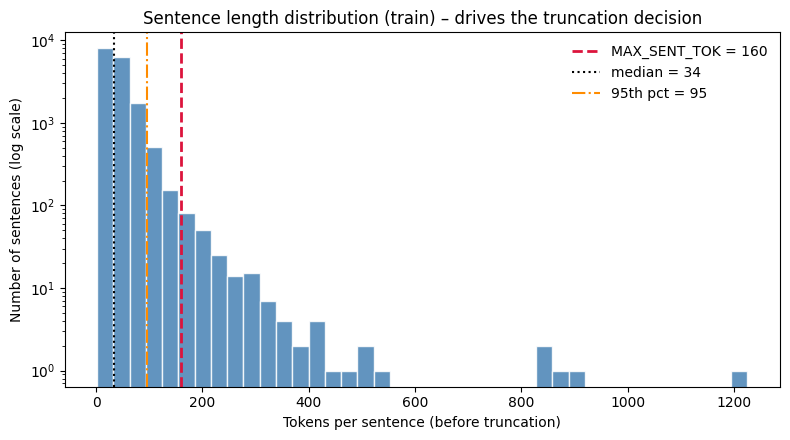

Sentences longer than MAX_SENT_TOK=160: 201 / 16845  (1.2%)
~99th percentile: 159 tokens


In [17]:
import matplotlib.pyplot as plt

# Raw (untruncated) token lengths — encode without the MAX_SENT_TOK cut
def raw_len(text):
    ids = tokenizer.encode(text)
    if ids and ids[0] == BOS: ids = ids[1:]
    if ids and ids[-1] == EOS: ids = ids[:-1]
    return len(ids)

sent_lens = []
for dom in DOMAINS:
    for d in DATA[(dom, "train")]:
        for s in d["sents"]:
            sent_lens.append(raw_len(s))
sent_lens = np.array(sent_lens)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(sent_lens, bins=40, color="steelblue", edgecolor="white", alpha=0.85, log=True)
ax.axvline(MAX_SENT_TOK, color="crimson", ls="--", lw=2, label=f"MAX_SENT_TOK = {MAX_SENT_TOK}")
ax.axvline(np.median(sent_lens), color="black", ls=":", lw=1.5,
           label=f"median = {int(np.median(sent_lens))}")
ax.axvline(np.percentile(sent_lens, 95), color="darkorange", ls="-.", lw=1.5,
           label=f"95th pct = {int(np.percentile(sent_lens, 95))}")
ax.set_xlabel("Tokens per sentence (before truncation)")
ax.set_ylabel("Number of sentences (log scale)")
ax.set_title("Sentence length distribution (train) – drives the truncation decision")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

n_over = (sent_lens > MAX_SENT_TOK).sum()
print(f"Sentences longer than MAX_SENT_TOK={MAX_SENT_TOK}: "
      f"{n_over} / {len(sent_lens)}  ({100 * n_over / len(sent_lens):.1f}%)")
print(f"~99th percentile: {int(np.percentile(sent_lens, 98.8))} tokens")

## 5. Finetuning Methods

In [40]:
class LoRALinear(nn.Module):
    """y = Wx + (alpha/r) * B(A x)   (additive low-rank update)."""
    def __init__(self, base, rank, alpha, dropout=0.0):
        super().__init__()
        self.base, self.scale = base, alpha / rank
        self.A = nn.Parameter(torch.empty(rank, base.in_features))
        self.B = nn.Parameter(torch.zeros(base.out_features, rank))
        self.drop = nn.Dropout(dropout)
        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
    def forward(self, x):
        return self.base(x) + self.scale * F.linear(F.linear(self.drop(x), self.A), self.B)

class LoRMALinear(nn.Module):
    """y = Wx + (alpha/r) * B(A(Wx))  ==  (I + s*BA) W x   (multiplicative low-rank update)."""
    def __init__(self, base, rank, alpha, dropout=0.0):
        super().__init__()
        self.base, self.scale = base, alpha / rank
        self.A = nn.Parameter(torch.empty(rank, base.out_features))
        self.B = nn.Parameter(torch.zeros(base.out_features, rank))
        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
    def forward(self, x):
        y = self.base(x)
        return y + self.scale * F.linear(F.linear(y, self.A), self.B)

class AdaLoRALinear(nn.Module):
    """Delta W = P diag(lambda * mask) Q. Orthogonality penalty + rank pruning (see AdaLoRAController)."""
    def __init__(self, base, rank, alpha, dropout=0.0):
        super().__init__()
        self.base, self.rank, self.scale = base, rank, alpha / rank
        self.P    = nn.Parameter(torch.empty(base.out_features, rank))
        self.diag = nn.Parameter(torch.zeros(rank))
        self.Q    = nn.Parameter(torch.empty(rank, base.in_features))
        self.register_buffer("mask", torch.ones(rank))           # 0 = pruned singular value
        nn.init.orthogonal_(self.P); nn.init.orthogonal_(self.Q)
    def orth_loss(self):
        eye = torch.eye(self.rank, device=self.P.device)
        return ((self.P.T @ self.P - eye) ** 2).sum() + ((self.Q @ self.Q.T - eye) ** 2).sum()
    def forward(self, x):
        low_rank = F.linear(x, self.Q) * (self.diag * self.mask)
        return self.base(x) + self.scale * F.linear(low_rank, self.P)

class AdaLoRAController:
    """Prunes singular values by smoothed sensitivity |lambda * grad| following a cubic budget schedule."""
    def __init__(self, modules, total_steps, final_ratio, warmup_frac=0.1, freeze_frac=0.2, prune_every=20, beta=0.85):
        self.modules, self.prune_every, self.beta = modules, prune_every, beta
        self.initial_budget = sum(m.rank for m in modules)
        self.final_budget = int(self.initial_budget * final_ratio)
        self.start_step = int(total_steps * warmup_frac)
        self.end_step = int(total_steps * (1 - freeze_frac))
        self.importance = [torch.zeros_like(m.diag) for m in modules]
    def budget_at(self, step):
        if step < self.start_step: return self.initial_budget
        if step >= self.end_step:  return self.final_budget
        progress = (step - self.start_step) / (self.end_step - self.start_step)
        return int(self.final_budget + (self.initial_budget - self.final_budget) * (1 - progress) ** 3)
    @torch.no_grad()
    def update(self, step):
        """Call after backward (grads unscaled), before optimizer.step()."""
        if step >= self.end_step:
            return
        for module, imp in zip(self.modules, self.importance):
            imp.mul_(self.beta).add_((1 - self.beta) * (module.diag * module.diag.grad).abs())
        if step >= self.start_step and step % self.prune_every == 0:
            all_scores = torch.cat(self.importance)
            budget = self.budget_at(step)
            threshold = torch.topk(all_scores, budget).values[-1]
            for module, imp in zip(self.modules, self.importance):
                module.mask.copy_((imp >= threshold).float())
    def active_rank(self):
        return int(sum(m.mask.sum().item() for m in self.modules))

class AdapterBlock(nn.Module):
    """Houlsby-style bottleneck adapter applied to the output of a transformer block."""
    def __init__(self, block, d_model, bottleneck):
        super().__init__()
        self.block = block
        self.down, self.up = nn.Linear(d_model, bottleneck), nn.Linear(bottleneck, d_model)
        nn.init.zeros_(self.up.weight); nn.init.zeros_(self.up.bias)
    def forward(self, x, position_ids, attn_mask=None, kv_cache=None, use_cache=False):
        h, cache = self.block(x, position_ids, attn_mask)
        return h + self.up(F.gelu(self.down(h))), cache

PEFT_WRAPPERS = {"lora": LoRALinear, "lorma": LoRMALinear, "adalora": AdaLoRALinear}
ATTN_PROJ_NAMES = ("q_proj", "k_proj", "v_proj", "out_proj", "kv_down_proj", "k_up_proj", "v_up_proj")  # GQA and MLA names

# Methods introduced in this phase. They plug into the shared toolkit from phase 2 (PEFT_WRAPPERS / METHOD_HOOKS / adapt_backbone).

class RsLoRALinear(LoRALinear):
    """Rank-stabilised LoRA: the update is scaled by alpha / sqrt(r) instead of alpha / r."""
    def __init__(self, base, rank, alpha, dropout=0.0):
        super().__init__(base, rank, alpha, dropout)
        self.scale = alpha / math.sqrt(rank)

class QLoRALinear(nn.Module):
    """Simulated QLoRA: frozen half-precision base weight + trainable LoRA update."""
    def __init__(self, base, rank, alpha, dropout=0.0):
        super().__init__()
        self.register_buffer("weight", base.weight.data.half())
        self.bias = None
        self.in_features, self.out_features = base.in_features, base.out_features
        self.A = nn.Parameter(torch.empty(rank, base.in_features))
        self.B = nn.Parameter(torch.zeros(base.out_features, rank))
        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
        self.scale = alpha / rank
        self.drop = nn.Dropout(dropout)
    def forward(self, x):
        return F.linear(x, self.weight.to(x.dtype)) + self.scale * F.linear(F.linear(self.drop(x), self.A), self.B)

class IA3Linear(nn.Module):
    """(IA)^3: learned per-channel scaling of the output (or input) of a frozen linear layer."""
    def __init__(self, base, where="out"):
        super().__init__()
        self.base, self.where = base, where
        for p in self.base.parameters():
            p.requires_grad = False
        self.s = nn.Parameter(torch.ones(base.out_features if where == "out" else base.in_features))
    def forward(self, x):
        return self.base(x * self.s.to(x.dtype)) if self.where == "in" else self.base(x) * self.s.to(x.dtype)

def apply_ia3(backbone, exp):
    """Scale the attention keys / values and the first feed-forward projection."""
    freeze(backbone)
    for block in backbone.blocks:
        attn = block.attn
        if hasattr(attn, "k_proj"):
            attn.k_proj, attn.v_proj = IA3Linear(attn.k_proj, "out"), IA3Linear(attn.v_proj, "out")
        elif hasattr(attn, "k_up_proj"):                             # MLA
            attn.k_up_proj, attn.v_up_proj = IA3Linear(attn.k_up_proj, "out"), IA3Linear(attn.v_up_proj, "out")
        ffn = getattr(block, "ffn", None)
        if ffn is not None:
            if hasattr(ffn, "gate"):
                ffn.gate = IA3Linear(ffn.gate, "out")
            elif hasattr(ffn, "net") and isinstance(ffn.net[0], nn.Linear):
                ffn.net[0] = IA3Linear(ffn.net[0], "out")

# register with the toolkit: low-rank variants are wrappers, the rest are hooks
METHOD_HOOKS = {}   # extra methods registered by later phases: name -> fn(backbone, exp)
PEFT_WRAPPERS.update({"rslora": RsLoRALinear, "qlora": QLoRALinear})
METHOD_HOOKS.update({"ia3": apply_ia3,
                     "prompt": lambda backbone, exp: freeze(backbone),          # only the soft prompt (+ head) is trained
                     "linear_probe": lambda backbone, exp: freeze(backbone)})   # only the head is trained

def moe_aux_loss(backbone):
    """Sum of the router load-balancing losses of all MoE feed-forward layers (0.0 for dense models)."""
    total = 0.0
    for block in backbone.blocks:
        if hasattr(block, "ffn") and hasattr(block.ffn, "aux_loss"):
            total = total + block.ffn.aux_loss
    return total

def wrap_attention_projections(backbone, wrapper_cls, rank, alpha, dropout=0.0):
    """Wrap every attention projection that exists in this architecture (GQA / MLA / conv variants)."""
    for block in backbone.blocks:
        for name in ATTN_PROJ_NAMES:
            if hasattr(block.attn, name):
                setattr(block.attn, name, wrapper_cls(getattr(block.attn, name), rank, alpha, dropout))

def freeze(module):
    for p in module.parameters():
        p.requires_grad = False


def adapt_backbone(base_lm, exp):
    """Phase 1 decoder -> backbone prepared for `exp.method` (optionally a shallower KD student)."""
    backbone = copy.deepcopy(base_lm)
    if exp.block_stride > 1:                                         # KD student: keep every n-th block
        keep = list(range(0, len(backbone.blocks), exp.block_stride))
        backbone.blocks = nn.ModuleList([backbone.blocks[i] for i in keep])
    d_model = backbone.cfg.d_model

    if exp.method in ("full", "unfreeze"):
        pass                                                         # everything trainable ("unfreeze" schedules it per epoch)
    elif exp.method == "partial":                                    # top-n blocks + final norm
        freeze(backbone)
        for block in backbone.blocks[-exp.n_top:]:
            for p in block.parameters(): p.requires_grad = True
        for p in backbone.ln_f.parameters(): p.requires_grad = True
    elif exp.method == "bitfit":                                     # bias terms only
        for name, p in backbone.named_parameters():
            p.requires_grad = name.endswith(".bias")
        assert any(p.requires_grad for p in backbone.parameters()), f"{exp.base_model} has no bias terms for BitFit"
    elif exp.method in PEFT_WRAPPERS:
        freeze(backbone)
        wrap_attention_projections(backbone, PEFT_WRAPPERS[exp.method], exp.rank, exp.alpha, exp.lora_dropout)
    elif exp.method == "adapter":
        freeze(backbone)
        backbone.blocks = nn.ModuleList([AdapterBlock(b, d_model, exp.adapter_dim) for b in backbone.blocks])
    elif exp.method in METHOD_HOOKS:                                 # registered by later phases (IA3, prompt tuning, linear probe, ...)
        METHOD_HOOKS[exp.method](backbone, exp)
    else:
        raise ValueError(f"unknown method: {exp.method}")
    return backbone

def count_params(model):
    total = sum(p.numel() for p in model.parameters()) / 1e6
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6
    return total, trainable

def apply_gradual_unfreezing(model, epoch, total_epochs):
    """Layer-unfreezing schedule: top blocks first, one more group of lower blocks every epoch."""
    blocks = model.backbone.blocks
    n_unfrozen = math.ceil(len(blocks) * (epoch + 1) / total_epochs)
    for i, block in enumerate(blocks):
        for p in block.parameters():
            p.requires_grad = i >= len(blocks) - n_unfrozen
    for p in model.backbone.ln_f.parameters(): p.requires_grad = True
    for p in model.backbone.tok_emb.parameters(): p.requires_grad = (n_unfrozen == len(blocks))

## 6. Training Utilities

In [41]:
class RRModel(nn.Module):
    """Sentence-level head: pooled sentence vectors (last token + mean), optional residual BiGRU over the sentences, optional soft prompt."""
    def __init__(self, backbone, head="bigru", pool="last_mean", n_prompt=0, dropout=HEAD_DROPOUT):
        super().__init__()
        self.backbone, self.pool, self.n_prompt = backbone, pool, n_prompt
        D = backbone.cfg.d_model
        pdim = 2 * D if pool == "last_mean" else D
        self.proj = nn.Sequential(nn.LayerNorm(pdim), nn.Dropout(dropout), nn.Linear(pdim, D), nn.GELU())
        self.ctx = nn.GRU(D, D // 2, batch_first=True, bidirectional=True) if head == "bigru" else None
        self.cls = nn.Sequential(nn.Dropout(dropout), nn.Linear(D, NUM_LABELS))
        if n_prompt:                                                 # soft prompt initialised from random token embeddings
            idx = torch.randint(0, backbone.tok_emb.weight.size(0), (n_prompt,))
            self.prompt = nn.Parameter((backbone.tok_emb.weight[idx] * backbone.emb_scale).detach().clone())

    def forward(self, ids, st, en, sm):
        h = encode_tokens(self.backbone, ids, None, True, GRAD_CKPT, self.prompt if self.n_prompt else None).float()
        B, T, D = h.shape
        cs = F.pad(h.cumsum(1), (0, 0, 1, 0))
        last = h.gather(1, (en - 1).clamp(min=0).unsqueeze(-1).expand(-1, -1, D))
        if self.pool == "last":
            rep = last
        else:
            mean = (cs.gather(1, en.unsqueeze(-1).expand(-1, -1, D)) - cs.gather(1, st.unsqueeze(-1).expand(-1, -1, D))) / (en - st).clamp(min=1).unsqueeze(-1)
            rep = torch.cat([last, mean], -1)
        z = self.proj(rep)
        if self.ctx is not None:                                     # document-level context across the sentences of a chunk
            lengths = sm.sum(1).cpu().clamp(min=1)
            packed = nn.utils.rnn.pack_padded_sequence(z.float(), lengths, batch_first=True, enforce_sorted=False)
            o, _ = self.ctx(packed)
            o, _ = nn.utils.rnn.pad_packed_sequence(o, batch_first=True, total_length=z.size(1))
            z = z + o.to(z.dtype)
        return self.cls(z), z

def effective_len(exp):
    """Token budget of a chunk (the soft prompt takes part of it)."""
    return CTX[exp.ctx]["max_len"] - (exp.n_prompt if exp.method == "prompt" else 0)

def build_model(base_lm, exp):
    backbone = adapt_backbone(base_lm, exp)
    n_prompt = exp.n_prompt if exp.method == "prompt" else 0
    return RRModel(backbone, CTX[exp.ctx]["head"], exp.pool, n_prompt).to(DEVICE)

def balanced_class_weights(labels, power=1.0, smooth=0.0, normalize=False):
    """Inverse-frequency class weights (total / (K * count)) ** power; `smooth` is added to the counts, `normalize` rescales to mean 1."""
    counts = np.bincount(labels, minlength=NUM_LABELS).astype(np.float64) + smooth
    w = (counts.sum() / (NUM_LABELS * counts)) ** power
    if normalize:
        w = w / w.mean()
    return torch.tensor(w, dtype=torch.float32, device=DEVICE)

def metrics(y, p):
    return dict(f1=f1_score(y, p, average="macro", zero_division=0), P=precision_score(y, p, average="macro", zero_division=0),
                R=recall_score(y, p, average="macro", zero_division=0), acc=accuracy_score(y, p),
                f1_all=f1_score(y, p, average="macro", labels=list(range(NUM_LABELS)), zero_division=0))

@torch.no_grad()
def predict(model, docs, ctxc, eff_len):
    """Returns per-document argmax labels and logits; every sentence is a target in exactly one chunk."""
    model.eval(); chunks = make_chunks(docs, ctxc, eff_len)
    chunks.sort(key=lambda ch: sum(len(x) for x in docs[ch[0]]["ids"][ch[1]:ch[3]]))        # similar lengths together: less padding
    logits = [np.zeros((len(d["sents"]), NUM_LABELS), np.float32) for d in docs]
    for b in batches(docs, chunks, ctxc["bs"] * 2):
        bd = to_dev(b)
        with autocast(DEVICE, dtype=AMP_DTYPE, enabled=USE_AMP):
            lg, _ = model(bd["ids"], bd["st"], bd["en"], bd["sm"])
        lg = lg.float().cpu().numpy()
        for r, (di, sidx, tml) in enumerate(zip(b["doc"], b["sidx"], b["tml"])):
            for q, (k, is_target) in enumerate(zip(sidx, tml)):
                if is_target: logits[di][k] = lg[r, q]
    return [l.argmax(1) for l in logits], logits

def eval_domains(model, dev_sets, ctxc, eff_len, doms):
    out = {}
    for dom in doms:
        pred, _ = predict(model, dev_sets[dom], ctxc, eff_len)
        out[dom] = metrics(np.concatenate([d["y"] for d in dev_sets[dom]]), np.concatenate(pred))
    return out

In [42]:
def encode_tokens(backbone, ids, attn=None, causal=True, use_ckpt=False, prompt=None):
    """Phase 1 decoder over right-padded [N, L] ids -> hidden states [N, L, D].
    causal=True : the pretrained left-to-right mask (padding never influences real tokens, so no mask is needed).
    causal=False: bidirectional attention with a key-padding mask built from `attn`.
    prompt      : optional [P, D] soft-prompt embeddings placed in front of the tokens (prompt tuning);
                  the returned states do not include the prompt positions."""
    N, L = ids.shape
    if attn is None:
        position_ids = torch.arange(L, device=ids.device).unsqueeze(0).expand(N, L)
    else:
        position_ids = (attn.long().cumsum(-1) - 1).clamp(min=0)
    x = backbone.tok_emb(ids) * backbone.emb_scale
    P = 0
    if prompt is not None:
        P = prompt.size(0)
        x = torch.cat([prompt.unsqueeze(0).expand(N, -1, -1).to(x.dtype), x], 1)
        prompt_pos = torch.arange(P, device=ids.device).unsqueeze(0).expand(N, P)
        position_ids = torch.cat([prompt_pos, position_ids + P], 1)
        if attn is not None:
            attn = torch.cat([attn.new_ones(N, P), attn], 1)
    if backbone.use_sin:
        x = x + backbone.pos_emb[position_ids]
    mask = None if (causal or attn is None) else attn[:, None, None, :].bool()
    for block in backbone.blocks:
        if use_ckpt and torch.is_grad_enabled():
            x = checkpoint(lambda h, blk=block: blk(h, position_ids, mask)[0], x, use_reentrant=False)
        else:
            x = block(x, position_ids, mask)[0]
    return backbone.ln_f(x)[:, P:]

def compute_loss(logits, labels, class_weights, loss_type):
    logits, labels = logits.float().reshape(-1, NUM_LABELS), labels.reshape(-1)
    if loss_type == "ce":                                            # no imbalance handling
        return F.cross_entropy(logits, labels, ignore_index=IGN)
    if loss_type == "weighted_ce":                                   # inverse-frequency class weights
        return F.cross_entropy(logits, labels, weight=class_weights, ignore_index=IGN)
    if loss_type == "focal":                                         # down-weights easy tokens + class weights
        keep = labels != IGN
        logits, labels = logits[keep], labels[keep]
        weighted_ce = F.cross_entropy(logits, labels, weight=class_weights, reduction="none")
        pt = torch.exp(-F.cross_entropy(logits, labels, reduction="none"))
        return (((1 - pt) ** FOCAL_GAMMA) * weighted_ce).mean()
    raise ValueError(loss_type)

def kd_loss(student_logits, teacher_logits, temperature):
    """Soft-target distillation: KL(teacher || student) at temperature T, scaled by T^2."""
    return F.kl_div(F.log_softmax(student_logits / temperature, -1), F.softmax(teacher_logits / temperature, -1),
                    reduction="batchmean") * temperature * temperature

def lr_factor(step, total_steps, warmup_frac):
    """Linear warm-up, then cosine decay (multiplier of the base learning rate)."""
    warmup = warmup_frac * total_steps
    if step < warmup:
        return (step + 1) / warmup
    return 0.5 * (1 + math.cos(math.pi * (step - warmup) / max(1, total_steps - warmup)))

## 7. Training Loop

In [43]:
def checkpoint_path(name):
    return f"{OUT}/ckpt_{name}.pt"     # latest epoch (resume point), overwritten every epoch

def best_path(name):
    return f"{OUT}/best_{name}.pt"     # best epoch only, kept separately

def save_atomic(obj, path):
    """Write to a temp file, then rename: an interruption can never corrupt the previous file."""
    torch.save(obj, path + ".tmp")
    os.replace(path + ".tmp", path)

def get_rng_state():
    return {"python": random.getstate(), "numpy": np.random.get_state(),
            "torch": torch.get_rng_state(), "cuda": torch.cuda.get_rng_state_all()}

def set_rng_state(state):
    random.setstate(state["python"]); np.random.set_state(state["numpy"])
    torch.set_rng_state(state["torch"]); torch.cuda.set_rng_state_all(state["cuda"])

def save_best(exp, best_state, best_metric, epoch):
    save_atomic({"state": best_state, "metric": best_metric, "epoch": epoch}, best_path(exp.name))

def save_epoch_checkpoint(exp, model, snapshot_keys, optimizer, scaler, adalora_ctrl, epoch, global_step, history):
    """Everything needed to continue training from the end of `epoch` (epochs completed so far)."""
    model_state = {k: v.detach().cpu() for k, v in model.state_dict().items() if k in snapshot_keys}
    save_atomic({"config": vars(exp), "epoch": epoch, "global_step": global_step, "history": history,
                 "model": model_state, "optimizer": optimizer.state_dict(), "scaler": scaler.state_dict(),
                 "adalora_importance": None if adalora_ctrl is None else [imp.cpu() for imp in adalora_ctrl.importance],
                 "rng": get_rng_state()}, checkpoint_path(exp.name))

def resume_if_checkpointed(exp, model, optimizer, scaler, adalora_ctrl, fresh_history, worst_metric):
    """Returns (start_epoch, global_step, history, best_metric, best_state).
    Fresh start values are returned when this experiment has no checkpoint yet."""
    if not os.path.exists(checkpoint_path(exp.name)):
        return 0, 0, fresh_history, worst_metric, None

    ckpt = torch.load(checkpoint_path(exp.name), map_location="cpu", weights_only=False)
    outcome = model.load_state_dict(ckpt["model"], strict=False)
    assert not outcome.unexpected_keys, outcome.unexpected_keys
    optimizer.load_state_dict(ckpt["optimizer"])
    scaler.load_state_dict(ckpt["scaler"])
    if adalora_ctrl is not None:
        for importance, saved in zip(adalora_ctrl.importance, ckpt["adalora_importance"]):
            importance.copy_(saved)
    set_rng_state(ckpt["rng"])

    best = torch.load(best_path(exp.name), map_location="cpu", weights_only=False)
    print(f"[{exp.name}] resumed after epoch {ckpt['epoch']}/{exp.epochs} (best so far {best['metric']:.4f} at epoch {best['epoch']})")
    return ckpt["epoch"], ckpt["global_step"], ckpt["history"], best["metric"], best["state"]

def snapshot_names(model, exp):
    """Parameters that must be restored to recover a given epoch."""
    if exp.method == "unfreeze":
        return set(model.state_dict().keys())
    trainable = {n for n, p in model.named_parameters() if p.requires_grad}
    return trainable | {k for k in model.state_dict() if k.endswith(".mask")}

In [44]:
def snapshot_names(model, exp):
    """Parameters that must be restored to recover a given epoch."""
    if exp.method == "unfreeze":
        return set(model.state_dict().keys())
    trainable = {n for n, p in model.named_parameters() if p.requires_grad}
    return trainable | {k for k in model.state_dict() if k.endswith(".mask")}

def train_model(model, exp, train_docs, dev_sets, teacher=None):
    ctxc = CTX[exp.ctx]
    eff_len = effective_len(exp)
    class_weights = None
    if exp.loss_type in ("weighted_ce", "focal"):
        class_weights = balanced_class_weights(np.concatenate([d["y"] for d in train_docs]), power=0.5, smooth=1.0, normalize=True)

    # backbone (adapters / soft prompt) and the new head get different learning rates; empty groups are skipped
    trainable = [(n, p) for n, p in model.named_parameters() if p.requires_grad]
    body_params = [p for n, p in trainable if n.startswith("backbone.") or n == "prompt"]
    head_params = [p for n, p in trainable if not (n.startswith("backbone.") or n == "prompt")]
    param_groups, base_lrs = [], []
    for params, lr in ((body_params, exp.lr), (head_params, exp.head_lr)):
        if params:
            param_groups.append({"params": params, "lr": lr}); base_lrs.append(lr)
    optimizer = torch.optim.AdamW(param_groups, weight_decay=WEIGHT_DECAY, betas=ADAM_BETAS)

    n_chunks = len(make_chunks(train_docs, ctxc, eff_len))
    steps_per_epoch = max(1, math.ceil(n_chunks / (ctxc["bs"] * ctxc["accum"])))
    total_steps = exp.epochs * steps_per_epoch
    scaler = GradScaler("cuda", enabled=USE_AMP and AMP_DTYPE == torch.float16)

    adalora_modules = [m for m in model.modules() if isinstance(m, AdaLoRALinear)]
    adalora_ctrl = AdaLoRAController(adalora_modules, total_steps, exp.adalora_final_ratio) if adalora_modules else None

    fresh_history = {"val_f1": [], "loss": [], "train_sec": 0.0, **{f"val_f1_{d}": [] for d in exp.train_domains}}
    start_epoch, global_step, history, best_score, best_state = resume_if_checkpointed(
        exp, model, optimizer, scaler, adalora_ctrl, fresh_history, worst_metric=-1.0)

    rng, bad, run_t0 = random, 0, time.time()                         # `random` is the global RNG, restored on resume
    for epoch in range(start_epoch, exp.epochs):
        t0 = time.time(); model.train()
        chunks = make_chunks(train_docs, ctxc, eff_len, train=True, rng=rng)
        epoch_loss, n_batches = 0.0, 0
        optimizer.zero_grad(set_to_none=True)
        progress = tqdm(batches(train_docs, chunks, ctxc["bs"], True, rng), total=math.ceil(len(chunks) / ctxc["bs"]),
                        desc=f"{exp.name} ep {epoch + 1}/{exp.epochs}", leave=False)
        for mi, b in enumerate(progress):
            bd = to_dev(b)
            with autocast(DEVICE, dtype=AMP_DTYPE, enabled=USE_AMP):
                logits, z = model(bd["ids"], bd["st"], bd["en"], bd["sm"])
                loss = compute_loss(logits, bd["y"], class_weights, exp.loss_type)
                if teacher is not None:                              # knowledge distillation: soft targets (+ optional representation match)
                    with torch.no_grad():
                        teacher_logits, teacher_z = teacher(bd["ids"], bd["st"], bd["en"], bd["sm"])
                    sel = bd["y"] != IGN
                    loss = exp.kd_ce_weight * loss + (1.0 - exp.kd_ce_weight) * kd_loss(logits[sel].float(), teacher_logits[sel].float(), exp.kd_temperature)
                    if exp.kd_rep_weight > 0:
                        loss = loss + exp.kd_rep_weight * (1 - F.cosine_similarity(z[sel].float(), teacher_z[sel].float(), dim=-1)).mean()
                if adalora_modules:                                  # keep P, Q near-orthogonal
                    loss = loss + ADALORA_ORTH_COEF * torch.stack([m.orth_loss() for m in adalora_modules]).mean()
                if MOE_AUX:
                    moe = moe_aux_loss(model.backbone)
                    if isinstance(moe, torch.Tensor):
                        loss = loss + moe
            scaler.scale(loss / ctxc["accum"]).backward()
            epoch_loss += loss.item(); n_batches += 1

            if (mi + 1) % ctxc["accum"] == 0:
                lr_frac = max(lr_factor(global_step, total_steps, WARMUP_FRAC), MIN_LR_FRAC)
                for group, base_lr in zip(optimizer.param_groups, base_lrs):
                    group["lr"] = base_lr * lr_frac
                scaler.unscale_(optimizer)
                grad_norm = torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], GRAD_CLIP)
                if adalora_ctrl is not None and torch.isfinite(grad_norm):
                    adalora_ctrl.update(global_step)
                scaler.step(optimizer); scaler.update(); optimizer.zero_grad(set_to_none=True)
                global_step += 1
            if (time.time() - run_t0) / 60 > MAX_MIN_PER_RUN:
                break

        # ── validation: model selection by the mean macro-F1 over the training domains ──
        dm = eval_domains(model, dev_sets, ctxc, eff_len, exp.train_domains)
        score = float(np.mean([dm[d]["f1"] for d in exp.train_domains]))
        history["val_f1"].append(score); history["loss"].append(epoch_loss / max(1, n_batches)); history["train_sec"] += time.time() - t0
        for d in exp.train_domains:
            history[f"val_f1_{d}"].append(dm[d]["f1"])
        extra = f" | active AdaLoRA rank {adalora_ctrl.active_rank()}/{adalora_ctrl.initial_budget}" if adalora_ctrl else ""
        print(f"[{exp.name}] ep {epoch + 1}/{exp.epochs} loss {history['loss'][-1]:.4f} | dev macro-F1 "
              + " ".join(f"{d}:{dm[d]['f1']:.4f}" for d in exp.train_domains) + f" | mean {score:.4f}{extra}")

        # ── checkpoints: best model (only when improved) first, then the resume point ──
        snapshot_keys = snapshot_names(model, exp)
        if score > best_score:
            best_score, bad = score, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items() if k in snapshot_keys}
            save_best(exp, best_state, best_score, epoch + 1)
        else:
            bad += 1
        save_epoch_checkpoint(exp, model, snapshot_keys, optimizer, scaler, adalora_ctrl, epoch + 1, global_step, history)

        if bad >= exp.patience:                                      # early stopping
            print(f"[{exp.name}] early stop: no improvement for {exp.patience} epochs"); break
        if (time.time() - run_t0) / 60 > MAX_MIN_PER_RUN:
            print(f"[{exp.name}] time cap ({MAX_MIN_PER_RUN} min)"); break

    model.load_state_dict(best_state, strict=False)                  # restore best epoch
    history["best_f1"] = best_score
    return history

## 8. Experiment Helper

In [45]:
@dataclass
class Experiment:
    name: str
    group: str                    # context | method | loss | domain | phase1 | kd | arch (used by the analysis plots)
    base_model: str               # one of PHASE1_CONFIGS
    method: str                   # linear_probe | full | lora | rslora | qlora | adalora | lorma | ia3 | prompt (+ partial | bitfit | adapter | unfreeze)
    ctx: str                      # key of CTX: sentence | window3 | doc | doc_bigru
    pool: str                     # last_mean | last
    loss_type: str                # ce | weighted_ce | focal
    train_domains: list           # subset of DOMAINS used for training and model selection
    epochs: int
    patience: int                 # early stopping (epochs without improvement)
    lr: float                     # backbone / adapter / soft-prompt learning rate
    head_lr: float                # sentence head learning rate
    rank: int                     # LoRA-family rank
    alpha: float
    lora_dropout: float
    n_top: int                    # blocks trained by "partial"
    adapter_dim: int
    adalora_final_ratio: float    # fraction of AdaLoRA ranks kept after pruning
    n_prompt: int                 # soft-prompt length ("prompt" method)
    block_stride: int             # 1 = all blocks; 2 = every 2nd block (KD student)
    random_init: bool             # True = same architecture without the Phase 1 weights (control)
    teacher_name: str             # experiment whose best weights act as the KD teacher (None = no KD)
    kd_temperature: float
    kd_ce_weight: float           # weight of the hard-label loss in the KD objective
    kd_rep_weight: float          # weight of the representation (cosine) distillation term
    seed: int

BASE = Experiment(name="", group="", base_model=MAIN_MODEL, method="lora", ctx="doc_bigru", pool="last_mean", loss_type="weighted_ce",
                  train_domains=list(DOMAINS), epochs=6, patience=3, lr=5e-4, head_lr=1e-3, rank=16, alpha=32.0, lora_dropout=0.05,
                  n_top=4, adapter_dim=64, adalora_final_ratio=0.5, n_prompt=32, block_stride=1, random_init=False,
                  teacher_name=None, kd_temperature=2.0, kd_ce_weight=0.5, kd_rep_weight=0.0, seed=SEED)

METHOD_HP = {"linear_probe": dict(head_lr=2e-3, lr=0.0),
             "full":         dict(lr=1e-4, epochs=6),
             "lora":         dict(rank=16, alpha=32.0, lr=5e-4),
             "rslora":       dict(rank=64, alpha=16.0, lr=5e-4),
             "qlora":        dict(rank=16, alpha=32.0, lr=5e-4),
             "adalora":      dict(rank=12, alpha=24.0, adalora_final_ratio=4 / 12, lr=1e-3),
             "lorma":        dict(rank=16, alpha=16.0, lr=5e-4),
             "ia3":          dict(lr=3e-3),
             "prompt":       dict(n_prompt=32, lr=3e-3)}

def make_exp(name, group, method="lora", **overrides):
    exp = replace(BASE, name=name, group=group, method=method, **{**METHOD_HP.get(method, {}), **overrides})
    cap = RS["max_epochs"]                                           # ablation / smoke modes cap the epochs
    return exp if cap is None else replace(exp, epochs=min(exp.epochs, cap))

# ── teacher (for KD): rebuilt from its saved config + best weights, so it survives a kernel restart ──
def load_teacher(exp):
    saved = json.load(open(f"{OUT}/result_{exp.teacher_name}.json"))
    teacher_exp = Experiment(**saved["config"])
    teacher = build_model(load_phase1_model(teacher_exp.base_model), teacher_exp)
    teacher.load_state_dict(torch.load(best_path(exp.teacher_name), map_location="cpu", weights_only=False)["state"], strict=False)
    teacher.eval(); freeze(teacher)
    return teacher

# ── results ──
def load_results():
    rows = []
    for file in sorted(os.listdir(OUT)):
        if file.startswith("result_") and file.endswith(".json"):
            r = json.load(open(f"{OUT}/{file}")); c = r["config"]
            rows.append({"name": r["name"], "group": c["group"], "model": c["base_model"], "method": c["method"], "ctx": c["ctx"],
                         "loss": c["loss_type"], "train": ",".join(c["train_domains"]), "trainable_M": r["trainable_M"], "total_M": r["total_M"],
                         "train_min": r["train_min"], "infer_s_per_1k": r["infer_s_per_1k"], "peak_GB": r["peak_GB"],
                         "F1_CL": r["F1_CL"], "F1_IT": r["F1_IT"], "F1": r["F1"]})
    cols = ["name", "group", "model", "method", "ctx", "loss", "train", "trainable_M", "total_M", "train_min", "infer_s_per_1k", "peak_GB", "F1_CL", "F1_IT", "F1"]
    return pd.DataFrame(rows, columns=cols).sort_values("F1", ascending=False).reset_index(drop=True)

# ── submission: {document id: [one label per sentence]} over both domains ──
def write_submission(model, exp):
    out = {}
    for dom in DOMAINS:
        docs = DATA[(dom, "test")]
        if not docs: continue
        pred, _ = predict(model, docs, CTX[exp.ctx], effective_len(exp))
        for d, p in zip(docs, pred):
            assert len(p) == len(d["sents"]) and d["id"] not in out, d["id"]
            out[d["id"]] = [LABELS[i] for i in p]
    json_path, zip_path = f"{OUT}/prediction_{exp.name}.json", f"{OUT}/submission_{exp.name}.zip"
    with open(json_path, "w", encoding="utf-8") as f:
        json.dump(out, f, ensure_ascii=False)
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
        z.write(json_path, "prediction.json")
    print(f"  -> {zip_path} ({len(out)} docs)")

def run_experiment(exp, keep_model=False):
    """Build -> train -> evaluate -> write submission -> save results. A finished experiment is restored from its checkpoint."""
    set_seed(exp.seed)
    base_lm = load_phase1_model(exp.base_model)
    if exp.random_init:
        base_lm = DecoderLM(base_lm.cfg)                             # same architecture, no Phase 1 weights
    model = build_model(base_lm, exp)
    del base_lm; gc.collect()
    total_m, trainable_m = count_params(model)
    print(f"\n=== {exp.name} | {exp.method} | ctx={exp.ctx} | train={exp.train_domains} | loss={exp.loss_type}: "
          f"total {total_m:.1f}M | trainable {trainable_m:.2f}M ({100 * trainable_m / total_m:.2f}%)")
    teacher = load_teacher(exp).to(DEVICE) if exp.teacher_name is not None else None

    train_docs = [d for dom in exp.train_domains for d in DATA[(dom, "train")]]
    dev_sets = {dom: DATA[(dom, "dev")] for dom in DOMAINS}
    if DEVICE == "cuda": torch.cuda.reset_peak_memory_stats()
    history = train_model(model, exp, train_docs, dev_sets, teacher)
    del teacher

    # dev evaluation of both domains (timed), per-class F1 and confusion matrices
    ctxc, eff_len = CTX[exp.ctx], effective_len(exp)
    result = {"name": exp.name, "config": vars(exp), "total_M": total_m, "trainable_M": trainable_m,
              "size_MB_fp32": total_m * 4 * 1e6 / 2**20, "dev": {}, "perclass": {}, "conf": {}}
    saved, n_sent, t0 = {}, 0, time.perf_counter()
    for dom in DOMAINS:
        pred, logits = predict(model, dev_sets[dom], ctxc, eff_len)
        y, p = np.concatenate([d["y"] for d in dev_sets[dom]]), np.concatenate(pred); n_sent += len(y)
        result["dev"][dom] = metrics(y, p)
        result["perclass"][dom] = f1_score(y, p, average=None, labels=list(range(NUM_LABELS)), zero_division=0).tolist()
        result["conf"][dom] = confusion_matrix(y, p, labels=list(range(NUM_LABELS))).tolist()
        saved.update({f"y_{dom}": y, f"p_{dom}": p, f"logits_{dom}": np.concatenate(logits)})
    result["infer_s_per_1k"] = (time.perf_counter() - t0) / max(n_sent, 1) * 1000
    result["peak_GB"] = torch.cuda.max_memory_allocated() / 2**30 if DEVICE == "cuda" else float("nan")
    result["F1_CL"], result["F1_IT"] = result["dev"]["CL"]["f1"], result["dev"]["IT"]["f1"]
    result["F1"] = (result["F1_CL"] + result["F1_IT"]) / 2
    result["train_min"] = history["train_sec"] / 60
    result["history"] = history
    np.savez_compressed(f"{OUT}/devpred_{exp.name}.npz", **saved)

    if RS["write_test"]:
        write_submission(model, exp)
    with open(f"{OUT}/result_{exp.name}.json", "w") as f:
        json.dump(result, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
    print(f"### {exp.name}: dev macro-F1  CL {result['F1_CL']:.4f} | IT {result['F1_IT']:.4f} | mean {result['F1']:.4f} | {result['train_min']:.1f} min")

    if keep_model:
        return model
    model.cpu(); del model; gc.collect(); torch.cuda.empty_cache()

def best_of(prefix):
    """Best finished experiment whose name starts with `prefix` (None if there is none)."""
    df = load_results(); df = df[df["name"].str.startswith(prefix)]
    return None if df.empty else df.iloc[0]

## 9. Smoke Test

In [28]:
for model_name in PHASE1_CONFIGS:
    lm = load_phase1_model(model_name)
    print(f"{model_name:22s} Phase-1 params: {sum(p.numel() for p in lm.parameters()) / 1e6:.1f}M")
    del lm
gc.collect(); torch.cuda.empty_cache()

gqa-rope               Phase-1 params: 65.7M
mla-sin                Phase-1 params: 91.5M
gqa-rope-swiglu-moe    Phase-1 params: 190.0M
swiglu-moe-rope-conv   Phase-1 params: 197.3M


## 10. Run Experiment

In [29]:
# Group 1: how much context helps (LoRA)
for ctx in ["sentence", "window3", "doc", "doc_bigru"]:
    run_experiment(make_exp(f"ctx_{ctx}", "context", "lora", ctx=ctx, epochs=4))

best_ctx = best_of("ctx_")
BEST_CTX = best_ctx["ctx"] if best_ctx is not None else "doc_bigru"
print("BEST CONTEXT:", BEST_CTX)


=== ctx_sentence | lora | ctx=sentence | train=['CL', 'IT'] | loss=weighted_ce: total 192.2M | trainable 2.18M (1.13%)


[ctx_sentence] ep 1/3 loss 1.9267 | dev macro-F1 CL:0.1874 IT:0.2161 | mean 0.2018


[ctx_sentence] ep 2/3 loss 1.3398 | dev macro-F1 CL:0.2354 IT:0.2707 | mean 0.2530


[ctx_sentence] ep 3/3 loss 0.8353 | dev macro-F1 CL:0.2408 IT:0.3348 | mean 0.2878
### ctx_sentence: dev macro-F1  CL 0.2408 | IT 0.3348 | mean 0.2878 | 9.0 min

=== ctx_window3 | lora | ctx=window3 | train=['CL', 'IT'] | loss=weighted_ce: total 192.2M | trainable 2.18M (1.13%)


[ctx_window3] ep 1/3 loss 1.5965 | dev macro-F1 CL:0.2674 IT:0.2476 | mean 0.2575


[ctx_window3] ep 2/3 loss 0.7209 | dev macro-F1 CL:0.3032 IT:0.3248 | mean 0.3140


... (3 outputs left out)

[ctx_doc] ep 3/3 loss 1.4412 | dev macro-F1 CL:0.3006 IT:0.1722 | mean 0.2364
### ctx_doc: dev macro-F1  CL 0.2902 | IT 0.2049 | mean 0.2476 | 4.4 min

=== ctx_doc_bigru | lora | ctx=doc_bigru | train=['CL', 'IT'] | loss=weighted_ce: total 194.9M | trainable 4.84M (2.48%)


[ctx_doc_bigru] ep 1/3 loss 2.3856 | dev macro-F1 CL:0.1578 IT:0.0926 | mean 0.1252


[ctx_doc_bigru] ep 2/3 loss 1.7815 | dev macro-F1 CL:0.2872 IT:0.2188 | mean 0.2530


[ctx_doc_bigru] ep 3/3 loss 1.4037 | dev macro-F1 CL:0.2922 IT:0.2310 | mean 0.2616
### ctx_doc_bigru: dev macro-F1  CL 0.2922 | IT 0.2310 | mean 0.2616 | 4.4 min
BEST CONTEXT: window3


In [46]:
# Group 2: fine-tuning / parameter-efficient techniques (full is also the KD teacher)
run_experiment(make_exp("m_full", "method", "full", ctx="doc_bigru", epochs=11))
for method in ["linear_probe", "lora", "rslora", "qlora", "adalora", "lorma", "ia3", "prompt"]:
    run_experiment(make_exp(f"m_{method}", "method", method, ctx="doc_bigru"))


=== m_full | full | ctx=doc_bigru | train=['CL', 'IT'] | loss=weighted_ce: total 193.9M | trainable 193.88M (100.00%)
[m_full] resumed after epoch 3/3 (best so far 0.3006 at epoch 3)
### m_full: dev macro-F1  CL 0.2758 | IT 0.3254 | mean 0.3006 | 5.1 min

=== m_linear_probe | linear_probe | ctx=doc_bigru | train=['CL', 'IT'] | loss=weighted_ce: total 193.9M | trainable 3.85M (1.99%)


[m_linear_probe] ep 1/3 loss 3.1754 | dev macro-F1 CL:0.2102 IT:0.1178 | mean 0.1640


[m_linear_probe] ep 2/3 loss 2.0489 | dev macro-F1 CL:0.2134 IT:0.1896 | mean 0.2015


[m_linear_probe] ep 3/3 loss 1.7699 | dev macro-F1 CL:0.2478 IT:0.1778 | mean 0.2128
### m_linear_probe: dev macro-F1  CL 0.2478 | IT 0.1778 | mean 0.2128 | 2.1 min

=== m_lora | lora | ctx=doc_bigru | train=['CL', 'IT'] | loss=weighted_ce: total 194.9M | trainable 4.84M (2.48%)


[m_lora] ep 1/3 loss 2.3856 | dev macro-F1 CL:0.1578 IT:0.0926 | mean 0.1252


[m_lora] ep 2/3 loss 1.7815 | dev macro-F1 CL:0.2872 IT:0.2188 | mean 0.2530


... (15 outputs left out)

[m_ia3] ep 3/3 loss 1.6608 | dev macro-F1 CL:0.2481 IT:0.1652 | mean 0.2066
### m_ia3: dev macro-F1  CL 0.2481 | IT 0.1652 | mean 0.2066 | 4.1 min

=== m_prompt | prompt | ctx=doc_bigru | train=['CL', 'IT'] | loss=weighted_ce: total 193.9M | trainable 3.88M (2.00%)


[m_prompt] ep 1/3 loss 2.3487 | dev macro-F1 CL:0.2530 IT:0.1264 | mean 0.1897


[m_prompt] ep 2/3 loss 1.8440 | dev macro-F1 CL:0.2345 IT:0.2589 | mean 0.2467


[m_prompt] ep 3/3 loss 1.5872 | dev macro-F1 CL:0.2661 IT:0.1964 | mean 0.2313
### m_prompt: dev macro-F1  CL 0.2345 | IT 0.2589 | mean 0.2467 | 4.2 min


In [47]:
# Group 3: class balancing (compare with ctx_<BEST_CTX>, weighted CE)
for loss_type in ["ce", "focal"]:
    run_experiment(make_exp(f"loss_{loss_type}", "loss", "lora", ctx=BEST_CTX, loss_type=loss_type, epochs=4))

# Group 4: domain transfer (train on one domain, both evaluated)
for dom in DOMAINS:
    run_experiment(make_exp(f"dom_{dom}", "domain", "lora", ctx=BEST_CTX, train_domains=[dom], epochs=4))

# Group 5: value of the Phase 1 weights (same architecture, random initialisation)
run_experiment(make_exp("p1_random_full", "phase1", "full", ctx=BEST_CTX, random_init=True, epochs=4))
run_experiment(make_exp("p1_random_lora", "phase1", "lora", ctx=BEST_CTX, random_init=True, epochs=4))


=== loss_ce | lora | ctx=window3 | train=['CL', 'IT'] | loss=ce: total 192.2M | trainable 2.18M (1.13%)


[loss_ce] ep 1/3 loss 1.4559 | dev macro-F1 CL:0.3149 IT:0.2100 | mean 0.2624


[loss_ce] ep 2/3 loss 0.6550 | dev macro-F1 CL:0.3039 IT:0.2948 | mean 0.2993


[loss_ce] ep 3/3 loss 0.2300 | dev macro-F1 CL:0.3067 IT:0.3036 | mean 0.3051
### loss_ce: dev macro-F1  CL 0.3067 | IT 0.3036 | mean 0.3051 | 23.0 min

=== loss_focal | lora | ctx=window3 | train=['CL', 'IT'] | loss=focal: total 192.2M | trainable 2.18M (1.13%)


[loss_focal] ep 2/3 loss 0.0818 | dev macro-F1 CL:0.2986 IT:0.3316 | mean 0.3151


[loss_focal] ep 3/3 loss 0.0287 | dev macro-F1 CL:0.2919 IT:0.3263 | mean 0.3091
### loss_focal: dev macro-F1  CL 0.2986 | IT 0.3316 | mean 0.3151 | 23.0 min

=== dom_CL | lora | ctx=window3 | train=['CL'] | loss=weighted_ce: total 192.2M | trainable 2.18M (1.13%)


... (8 outputs left out)

[p1_random_full] ep 3/3 loss 0.5301 | dev macro-F1 CL:0.2075 IT:0.1281 | mean 0.1678
### p1_random_full: dev macro-F1  CL 0.2489 | IT 0.1568 | mean 0.2029 | 28.2 min

=== p1_random_lora | lora | ctx=window3 | train=['CL', 'IT'] | loss=weighted_ce: total 192.2M | trainable 2.18M (1.13%)


[p1_random_lora] ep 1/3 loss 2.1603 | dev macro-F1 CL:0.1484 IT:0.1272 | mean 0.1378


[p1_random_lora] ep 2/3 loss 1.4696 | dev macro-F1 CL:0.2009 IT:0.0971 | mean 0.1490


[p1_random_lora] ep 3/3 loss 0.8551 | dev macro-F1 CL:0.2045 IT:0.1227 | mean 0.1636
### p1_random_lora: dev macro-F1  CL 0.2045 | IT 0.1227 | mean 0.1636 | 23.0 min


In [48]:
# Group 6: knowledge distillation. Teacher = m_full. Student = every 2nd block of the same Phase 1 model.
STUDENT = dict(block_stride=2, lr=2e-4, epochs=6)
run_experiment(make_exp("kd_student_ce", "kd", "full", ctx=BEST_CTX, **STUDENT))                       # control: no teacher
run_experiment(make_exp("kd_student_logits", "kd", "full", ctx=BEST_CTX, teacher_name="m_full",
                        kd_temperature=2.0, kd_ce_weight=0.3, kd_rep_weight=0.0, **STUDENT))           # soft targets
run_experiment(make_exp("kd_student_logits_rep", "kd", "full", ctx=BEST_CTX, teacher_name="m_full",
                        kd_temperature=2.0, kd_ce_weight=0.3, kd_rep_weight=0.5, **STUDENT))           # soft targets + representation match


=== kd_student_ce | full | ctx=window3 | train=['CL', 'IT'] | loss=weighted_ce: total 103.9M | trainable 103.89M (100.00%)


[kd_student_ce] ep 1/3 loss 1.5869 | dev macro-F1 CL:0.1633 IT:0.1932 | mean 0.1783


[kd_student_ce] ep 2/3 loss 0.5742 | dev macro-F1 CL:0.2342 IT:0.2870 | mean 0.2606


[kd_student_ce] ep 3/3 loss 0.1398 | dev macro-F1 CL:0.2259 IT:0.2390 | mean 0.2325
### kd_student_ce: dev macro-F1  CL 0.2342 | IT 0.2870 | mean 0.2606 | 14.2 min

=== kd_student_logits | full | ctx=window3 | train=['CL', 'IT'] | loss=weighted_ce: total 103.9M | trainable 103.89M (100.00%)


[kd_student_logits] ep 2/3 loss 0.3891 | dev macro-F1 CL:0.2879 IT:0.2906 | mean 0.2893


[kd_student_logits] ep 3/3 loss 0.2762 | dev macro-F1 CL:0.2782 IT:0.3007 | mean 0.2894
### kd_student_logits: dev macro-F1  CL 0.2782 | IT 0.3007 | mean 0.2894 | 23.5 min

=== kd_student_logits_rep | full | ctx=window3 | train=['CL', 'IT'] | loss=weighted_ce: total 103.9M | trainable 103.89M (100.00%)


[kd_student_logits_rep] ep 1/3 loss 0.9442 | dev macro-F1 CL:0.2218 IT:0.2445 | mean 0.2331


[kd_student_logits_rep] ep 2/3 loss 0.5017 | dev macro-F1 CL:0.2782 IT:0.3030 | mean 0.2906


[kd_student_logits_rep] ep 3/3 loss 0.3769 | dev macro-F1 CL:0.2608 IT:0.3077 | mean 0.2842
### kd_student_logits_rep: dev macro-F1  CL 0.2782 | IT 0.3030 | mean 0.2906 | 23.5 min


In [49]:
# Group 7: the same technique (LoRMA) on every Phase 1 architecture (the spec asks for submissions from different Phase 1 models)
for model_name in PHASE1_CONFIGS:
    run_experiment(make_exp(f"arch_lorma_{model_name}", "arch", "lorma", ctx=BEST_CTX, base_model=model_name))


=== arch_lorma_gqa-rope | lorma | ctx=window3 | train=['CL', 'IT'] | loss=weighted_ce: total 67.5M | trainable 1.72M (2.55%)


[arch_lorma_gqa-rope] ep 1/3 loss 1.6164 | dev macro-F1 CL:0.2392 IT:0.2551 | mean 0.2471


[arch_lorma_gqa-rope] ep 2/3 loss 0.8581 | dev macro-F1 CL:0.2727 IT:0.2807 | mean 0.2767


[arch_lorma_gqa-rope] ep 3/3 loss 0.4067 | dev macro-F1 CL:0.2741 IT:0.2830 | mean 0.2786
### arch_lorma_gqa-rope: dev macro-F1  CL 0.2741 | IT 0.2830 | mean 0.2786 | 11.6 min

=== arch_lorma_mla-sin | lorma | ctx=window3 | train=['CL', 'IT'] | loss=weighted_ce: total 94.0M | trainable 2.45M (2.60%)


[arch_lorma_mla-sin] ep 1/3 loss 1.7861 | dev macro-F1 CL:0.2221 IT:0.2208 | mean 0.2215


[arch_lorma_mla-sin] ep 2/3 loss 1.2756 | dev macro-F1 CL:0.2766 IT:0.2308 | mean 0.2537


... (3 outputs left out)

[arch_lorma_gqa-rope-swiglu-moe] ep 3/3 loss 0.4836 | dev macro-F1 CL:0.2796 IT:0.3256 | mean 0.3026
### arch_lorma_gqa-rope-swiglu-moe: dev macro-F1  CL 0.2919 | IT 0.3884 | mean 0.3401 | 22.4 min

=== arch_lorma_swiglu-moe-rope-conv | lorma | ctx=window3 | train=['CL', 'IT'] | loss=weighted_ce: total 199.3M | trainable 1.98M (0.99%)


[arch_lorma_swiglu-moe-rope-conv] ep 1/3 loss 1.5708 | dev macro-F1 CL:0.2022 IT:0.2899 | mean 0.2460


[arch_lorma_swiglu-moe-rope-conv] ep 2/3 loss 0.8234 | dev macro-F1 CL:0.2514 IT:0.3308 | mean 0.2911


[arch_lorma_swiglu-moe-rope-conv] ep 3/3 loss 0.3785 | dev macro-F1 CL:0.2428 IT:0.2554 | mean 0.2491
### arch_lorma_swiglu-moe-rope-conv: dev macro-F1  CL 0.2514 | IT 0.3308 | mean 0.2911 | 24.3 min


                           name   group                model       method       ctx        loss train  trainable_M  total_M  train_min  infer_s_per_1k  peak_GB  F1_CL  F1_IT     F1
 arch_lorma_gqa-rope-swiglu-moe    arch  gqa-rope-swiglu-moe        lorma   window3 weighted_ce CL,IT       1.9799 192.0031    22.4371         16.9284   7.2668 0.2919 0.3884 0.3401
arch_lorma_swiglu-moe-rope-conv    arch swiglu-moe-rope-conv        lorma   window3 weighted_ce CL,IT       1.9799 199.2930    24.3363         18.4957   7.5618 0.2514 0.3308 0.2911
            arch_lorma_gqa-rope    arch             gqa-rope        lorma   window3 weighted_ce CL,IT       1.7178  67.4663    11.5537          9.1454   3.8881 0.2741 0.2830 0.2786
             arch_lorma_mla-sin    arch              mla-sin        lorma   window3 weighted_ce CL,IT       2.4469  93.9786    17.4801         13.5123   5.6925 0.2766 0.2308 0.2537
                    ctx_window3 context  gqa-rope-swiglu-moe         lora   window3 weighted_ce

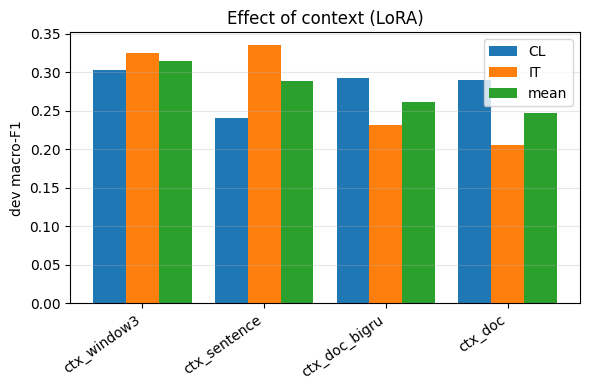

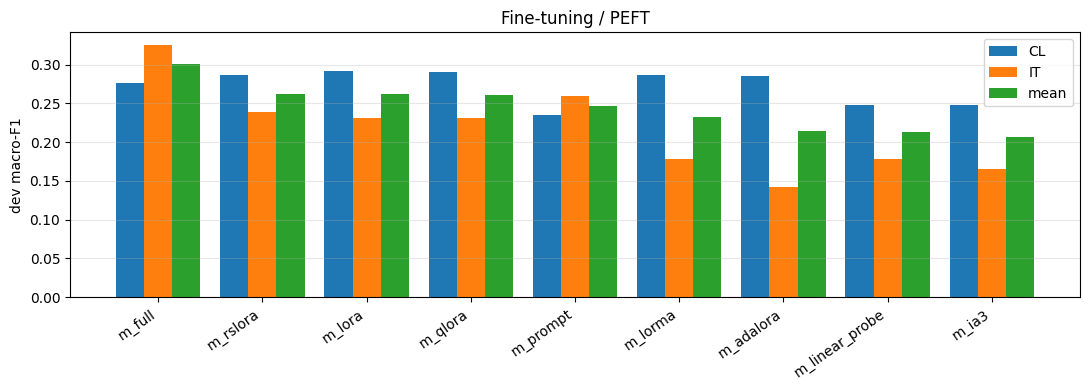

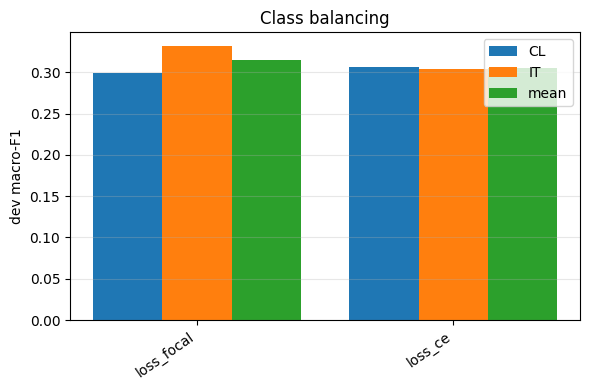

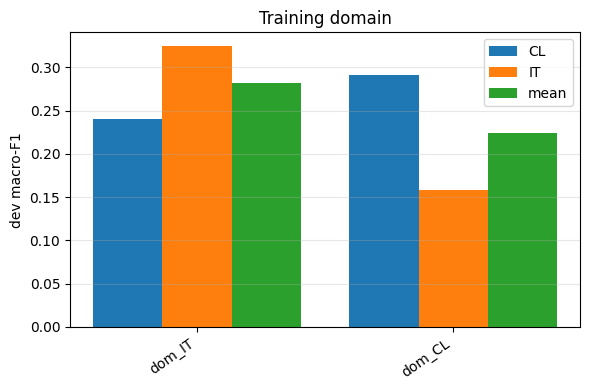

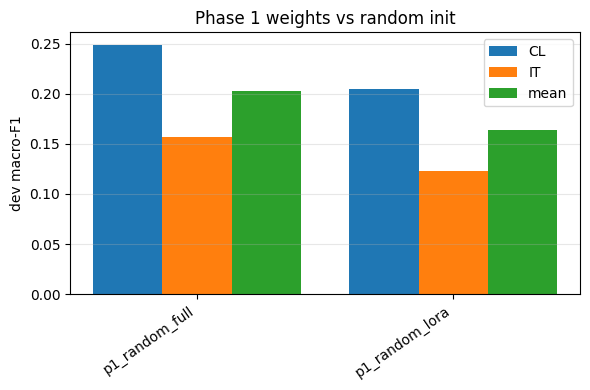

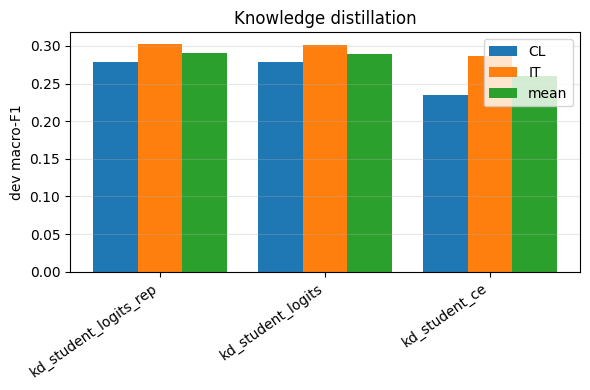

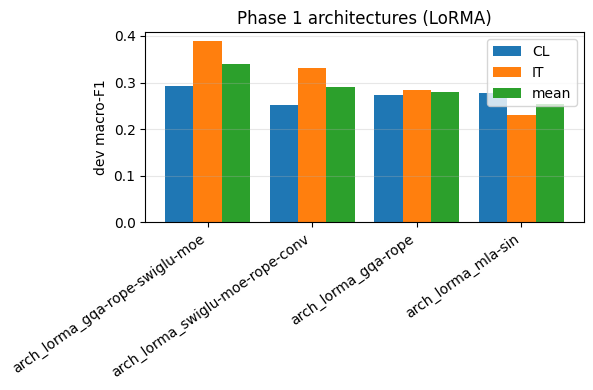

In [50]:
results_df = load_results()
pd.set_option("display.width", 250, "display.max_columns", 30)
print(results_df.sort_values(["group", "F1"], ascending=[True, False]).round(4).to_string(index=False))
results_df.to_csv(f"{OUT}/summary.csv", index=False)

def bar_group(group, title=None):
    d = results_df[results_df.group == group].sort_values("F1", ascending=False)
    if d.empty: return
    x = np.arange(len(d))
    fig, ax = plt.subplots(figsize=(max(6, 1.0 * len(d) + 2), 4))
    ax.bar(x - .27, d.F1_CL, .27, label="CL"); ax.bar(x, d.F1_IT, .27, label="IT"); ax.bar(x + .27, d.F1, .27, label="mean")
    ax.set_xticks(x); ax.set_xticklabels(d["name"], rotation=35, ha="right")
    ax.set_ylabel("dev macro-F1"); ax.set_title(title or group); ax.legend(); ax.grid(axis="y", alpha=.3)
    plt.tight_layout(); plt.savefig(f"{OUT}/{group}.png", dpi=150); plt.show()

for group, title in [("context", "Effect of context (LoRA)"), ("method", "Fine-tuning / PEFT"), ("loss", "Class balancing"),
                     ("domain", "Training domain"), ("phase1", "Phase 1 weights vs random init"), ("kd", "Knowledge distillation"),
                     ("arch", "Phase 1 architectures (LoRMA)")]:
    bar_group(group, title)

In [51]:
def error_analysis(name, top=6):
    r = json.load(open(f"{OUT}/result_{name}.json"))
    for dom in DOMAINS:
        f1s, conf = r["perclass"][dom], np.array(r["conf"][dom])
        print(f"\n{name} | {dom}: macro-F1 {r['dev'][dom]['f1']:.4f}")
        print("  per-role F1:", {LABELS[i]: round(f1s[i], 3) for i in np.argsort(f1s)})
        off = conf.copy(); np.fill_diagonal(off, 0)
        pairs = sorted(((off[i, j], LABELS[i], LABELS[j]) for i in range(NUM_LABELS) for j in range(NUM_LABELS) if off[i, j] > 0), reverse=True)[:top]
        print("  most confused (true -> predicted):", [(a, b, int(n)) for n, a, b in pairs])

error_analysis(results_df.loc[0, "name"])      # best experiment on dev


arch_lorma_gqa-rope-swiglu-moe | CL: macro-F1 0.2919
  per-role F1: {'Issue': 0.0, 'Dissent': 0.0, 'PrecedentNotReliedUpon': 0.0, 'PrecedentOverruled': 0.0, 'None': 0.0, 'RulingByLowerCourt': 0.119, 'ArgumentRespondent': 0.199, 'RulingByPresentCourt': 0.353, 'PrecedentReliedUpon': 0.378, 'ArgumentPetitioner': 0.41, 'RatioOfTheDecision': 0.426, 'Fact': 0.54, 'Statute': 0.787}
  most confused (true -> predicted): [('ArgumentPetitioner', 'RatioOfTheDecision', 64), ('Fact', 'RatioOfTheDecision', 57), ('PrecedentReliedUpon', 'RatioOfTheDecision', 50), ('ArgumentRespondent', 'ArgumentPetitioner', 43), ('ArgumentRespondent', 'RatioOfTheDecision', 25), ('ArgumentPetitioner', 'Fact', 24)]

arch_lorma_gqa-rope-swiglu-moe | IT: macro-F1 0.3884
  per-role F1: {'Dissent': 0.0, 'PrecedentReliedUpon': 0.0, 'Statute': 0.0, 'PrecedentOverruled': 0.0, 'RulingByLowerCourt': 0.0, 'None': 0.2, 'ArgumentRespondent': 0.346, 'ArgumentPetitioner': 0.364, 'PrecedentNotReliedUpon': 0.492, 'Issue': 0.545, 'Ratio

In [52]:
def write_best_per_model(df):
    """Best experiment of every Phase 1 model -> submission_best_<model>.zip (one submission per architecture)."""
    for model_name, group in df.groupby("model"):
        best = group.sort_values("F1", ascending=False).iloc[0]["name"]
        src = f"{OUT}/submission_{best}.zip"
        if os.path.exists(src):
            shutil.copy(src, f"{OUT}/submission_best_{model_name}.zip")
            print(f"{model_name:22s} <- {best:28s} dev F1 {group['F1'].max():.4f}")

# Submissions: the best four *different techniques* (KD counts as one), as the spec requires
candidates = results_df[results_df.group.isin(["method", "kd"])].sort_values("F1", ascending=False)
SUBMIT, seen = [], set()
best_kd = candidates[candidates.group == "kd"]["name"].tolist()[:1]
for _, r in candidates.iterrows():
    technique = "kd" if r.group == "kd" else r.method
    if technique in seen or r.method == "linear_probe":
        continue
    seen.add(technique); SUBMIT.append(r["name"])
    if len(SUBMIT) == 4:
        break
if best_kd and best_kd[0] not in SUBMIT and SUBMIT:
    SUBMIT[-1] = best_kd[0]
print("submissions:", SUBMIT)

if RS["write_test"]:
    for name in SUBMIT:
        print(name, "->", f"{OUT}/submission_{name}.zip", "(ok)" if os.path.exists(f"{OUT}/submission_{name}.zip") else "(MISSING)")
    write_best_per_model(results_df)
else:
    print(f"RUN_MODE={RUN_MODE}: no test predictions were written (analysis only)")

submissions: ['m_full', 'kd_student_logits_rep', 'm_rslora', 'm_lora']
RUN_MODE=ablation: no test predictions were written (analysis only)
